# Neuro-GRAPE v3: multi-seed, heterogeneous-group study on **MNE-Python** EEG/MEG (Google Colab)
**Group-Robust Adaptive Pretraining for Heterogeneous Neural Modalities**

v3 = the v2 study (multi-seed, heterogeneous groups, paired statistics, representation-vs-weighting diagnostics, checkpointing) with the **whole data path rebuilt on [MNE-Python](https://mne.tools)**. Everything downstream of Stage 0 (BrainTokenizer, Criss-Cross backbone, DoReMi / GRAPE / Neuro-GRAPE engine, statistics, diagnostics) is the v2 code.

| What changed vs v2 | Why |
|---|---|
| **`DATA_SOURCE = "mne_real"`**: real EEG/MEG read with `mne.io`, preprocessed with MNE (channel harmonisation, notch, 0.5-45 Hz band-pass, resample to 128 Hz, average reference), cut into 2 s windows | v2 was simulation only. This is the "swap `make_group_data()`" step v2 promised |
| **Sensor geometry from `mne.Info`** (`sensor_tensors`): 3-D positions, MEG coil normals, EEG/grad/mag type, `dev_head_t` applied | the tokenizer's sensor encoder now sees real layouts instead of random points on a sphere |
| **`DATA_SOURCE = "mne_sim"`**: the v2 simulator, but on real MNE geometry (standard 10-05 electrodes, Vectorview / CTF-275 MEG layouts) and passed through `mne.EpochsArray` | same code path as real data; lets you run the full study offline and compare |
| **Leak-free splits**: by recording/subject when there are ≥ 6 recordings, otherwise by contiguous time blocks with block-straddling windows dropped | random window splits of continuous EEG/MEG leak information between train and test |
| **Partially labelled data**: labels are `-1` where a dataset has none; downstream head/metrics are masked, **balanced accuracy** is used on real data, GRAPE tasks are built only from labels that exist | public EEG/MEG corpora do not share one label set |
| **Data provenance** printed and saved (REAL vs SIMULATED per group) | so a table can never be mistaken for the wrong kind of evidence |

**Scope of the claims.** With `mne_sim`, results are simulation-based evidence only. With `mne_real`, results are evidence on **the datasets listed in the provenance table** (by default small public MNE datasets used as stand-ins; see Stage 0c). They are *not* results on TUH / CHB-MIT / OMEGA / Cam-CAN unless you point the `kind="local"` entries at those corpora.

Run top to bottom. Set `QUICK = True` first (minutes) to smoke-test, then switch it off for the full study.

In [ ]:
import os, sys, time, math, json, subprocess
from dataclasses import dataclass
from types import SimpleNamespace
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
try:
    import mne
except ImportError:                      # Colab does not ship MNE
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mne"], check=True); import mne

# ======================= experiment switches =======================
QUICK     = bool(int(os.environ.get("NG_QUICK", "0")))   # True = tiny smoke test (set here or via env var)
DATA_SOURCE = os.environ.get("NG_DATA", "mne_real")   # "mne_real" (EEG/MEG read with MNE) | "mne_sim" (v2 simulator on MNE geometry)
SCENARIO  = "hetero"        # only used when DATA_SOURCE="mne_sim": "hetero" (genuinely different groups) | "original" (v1 structure)
N_SEEDS   = 2 if QUICK else 5
INCLUDE_EXTRA_FIXED = True  # also run EEG-heavy / MEG-heavy fixed mixtures (proposal slide 5); False saves 2 runs/seed
RESAMPLE_LAYOUT = True      # new sensor layouts for every seed (tests robustness to layout, not one lucky geometry)
RUN_ALPHA_SWEEP = True;  SWEEP_SEEDS = 1 if QUICK else 3     # weighting-only control (see Diagnostics)
RUN_TOK_ABLATION = True; ABL_SEEDS   = 1 if QUICK else 3     # better-tokenizer control (see Diagnostics)
SWEEP_W = [0.10, 0.25, 0.40, 0.55, 0.70]                      # weight given to the hardest group
RESULT_DIR = "results"; os.makedirs(RESULT_DIR, exist_ok=True)
TAG = ("real" if DATA_SOURCE == "mne_real" else SCENARIO) + ("_quick" if QUICK else "")   # (real mode appends the group names in Stage 0d)

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev, "| data:", DATA_SOURCE, "| MNE", mne.__version__, "| scenario:", SCENARIO, "| seeds:", N_SEEDS, "| QUICK:", QUICK)

def set_seed(s):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

device: cuda | data: mne_real | MNE 1.13.2 | scenario: hetero | seeds: 5 | QUICK: False


## Configuration and group specifications
Each group now differs along several axes at once:

| field | meaning |
|---|---|
| `mod`, `C` | modality and number of sensors (different layouts, 14-32 channels) |
| `noise` | noise amplitude; `ncol` = smoothing kernel of the noise (larger = more low-frequency, "pink-ish" noise that overlaps the slowing band) |
| `snr` | gain on the neural sources (lower = harder) |
| `fshift`, `fscale` | additive shift and multiplicative scaling of all rhythm frequencies (different frequency patterns) |
| `art` | probability of a slow-drift artifact (blink / movement-like) across channels |
| `spike_amp` | amplitude of the spike burst event |
| `n_train` | pretraining windows (**unequal group sizes**; small groups are over-sampled under Uniform, so they can overfit) |

Which group ends up hardest is *measured*, not assumed.

In [ ]:
@dataclass
class Cfg:
    # signal / token grid
    T: int = 256            # samples per window (2 s at 128 Hz)
    FS: int = 128
    D: int = 32             # tokenizer width
    Cq: int = 8             # C' latent brain sources
    Kc: int = 64            # RVQ codebook size
    Nq: int = 4             # RVQ layers
    # backbone
    Dm: int = 64
    layers: int = 3
    heads: int = 4
    mask_ratio: float = 0.5
    # data (val/test are the SAME size for every group so group metrics are comparable)
    n_val: int = 300        # proxy-validation split: used by GRAPE targets / hardest-group choice, never the test set
    n_test: int = 300
    n_finetune: int = 250   # labelled windows per group for the downstream head (<= smallest group)
    # optimisation (identical for ref / proxy / final runs)
    tok_steps: int = 600
    bb_steps: int = 500
    tok_bs: int = 16
    bg: int = 12
    lr_tok: float = 2e-3
    lr_bb: float = 2e-3
    # Neuro-GRAPE
    smooth_c: float = 1e-3
    eta_dro: float = 1.0
    eta_alpha: float = 1.0
    eta_z: float = 5.0
    align_every: int = 5
    task_bs: int = 16
    warmup_frac: float = 0.1

cfg = Cfg()
if QUICK:
    cfg.n_val, cfg.n_test, cfg.n_finetune = 80, 80, 60
    cfg.tok_steps, cfg.bb_steps, cfg.bg, cfg.align_every = 40, 40, 6, 4
cfg.W = cfg.T // 16

GROUPS = ["TUH", "CHB-MIT", "OMEGA", "Cam-CAN"]
K = len(GROUPS)

SCENARIOS = {
    # v1 group structure (equal sizes, equal SNR, same noise colour) for comparison
    "original": {
        "TUH":     dict(mod="EEG", C=19, noise=0.5, snr=1.0, fshift=0.0,  fscale=1.0, ncol=3, art=0.0, spike_amp=3.0, n_train=1000),
        "CHB-MIT": dict(mod="EEG", C=23, noise=1.0, snr=1.0, fshift=1.0,  fscale=1.0, ncol=3, art=0.0, spike_amp=3.0, n_train=1000),
        "OMEGA":   dict(mod="MEG", C=24, noise=0.4, snr=1.0, fshift=0.5,  fscale=1.0, ncol=3, art=0.0, spike_amp=3.0, n_train=1000),
        "Cam-CAN": dict(mod="MEG", C=20, noise=1.2, snr=1.0, fshift=-0.5, fscale=1.0, ncol=3, art=0.0, spike_amp=3.0, n_train=1000),
    },
    # new: different layouts, SNR, noise colour, frequency patterns, artifacts and group sizes
    "hetero": {
        "TUH":     dict(mod="EEG", C=19, noise=0.5, snr=1.0, fshift=0.0,  fscale=1.00, ncol=3, art=0.00, spike_amp=3.0, n_train=1200),
        "CHB-MIT": dict(mod="EEG", C=23, noise=0.9, snr=0.8, fshift=1.0,  fscale=1.10, ncol=5, art=0.15, spike_amp=2.5, n_train=800),
        "OMEGA":   dict(mod="MEG", C=32, noise=0.4, snr=1.2, fshift=0.5,  fscale=1.00, ncol=3, art=0.00, spike_amp=3.0, n_train=500),
        "Cam-CAN": dict(mod="MEG", C=14, noise=1.1, snr=0.6, fshift=-0.8, fscale=0.90, ncol=9, art=0.30, spike_amp=2.0, n_train=250),
    },
}
SPECS = {g: dict(s) for g, s in SCENARIOS[SCENARIO].items()}
if QUICK:
    for g in SPECS: SPECS[g]["n_train"] = max(100, int(0.2 * SPECS[g]["n_train"]))
NTRAIN = {g: SPECS[g]["n_train"] for g in GROUPS}

FIXED_MIXTURES = {
    "Uniform":   [0.25, 0.25, 0.25, 0.25],
    "EEG-heavy": [0.375, 0.375, 0.125, 0.125],
    "MEG-heavy": [0.125, 0.125, 0.375, 0.375],
}
ORDER = ["Uniform", "EEG-heavy", "MEG-heavy", "DoReMi", "GRAPE", "Neuro-GRAPE"]

# GRAPE target tasks: (name, label column, group mixture the task cares about). Defined on the VAL split only.
TASKS = [
    ("AD65-like (slowing)",          0, [0.5, 0.5, 0.0, 0.0]),
    ("TUAB-like (spike/abnormal)",   1, [0.3, 0.7, 0.0, 0.0]),
    ("SomatoMotor-like (laterality)", 2, [0.0, 0.0, 0.5, 0.5]),
]
N_TASK = len(TASKS)

try:
    import pandas as pd
    def show(df):
        try: display(df)
        except NameError: print(df)
    if DATA_SOURCE == "mne_sim": show(pd.DataFrame(SPECS).T)
except ImportError:
    print(SPECS)

## Stage 0: EEG/MEG data layer built on MNE-Python
Every group, simulated or real, is reduced to the same four things: `X (n, C, T)` windows at 128 Hz (T = 256 = 2 s), `y (n, 3)` labels (`-1` = unavailable), and the sensor description `L (C, 6)` + `types (C,)` produced by `sensor_tensors(mne.Info)`.

**0a helpers** - geometry from `mne.Info`, EEG name → 10-05 position, farthest-point channel thinning, window QC, robust scaling, MNE-PSD spectral-slowing label.
**0b `mne_sim`** - v2 simulator on real MNE layouts, wrapped in `mne.EpochsArray`.
**0c `mne_real`** - recording openers + MNE preprocessing + windowing. Group definitions live in `REAL_GROUP_DEFS`:

| `kind` | data | notes |
|---|---|---|
| `eegbci` | PhysioNet EEG Motor Movement/Imagery via `mne.datasets.eegbci` (64-ch EEG, many subjects) | eyes-open/closed baselines + left/right-fist runs; labels from the `T0/T1/T2` annotations |
| `sample` | `mne.datasets.sample` (Neuromag, 60 EEG + 306 MEG, one subject) - used as one EEG group and one MEG group | left/right auditory+visual stimulus events give the laterality label (event-locked windows) |
| `somato` | `mne.datasets.somato` (Neuromag MEG, one subject, median-nerve stimulation) | stimulus-locked vs baseline windows |
| `local` | **your corpus on disk** (TUH / CHB-MIT / OMEGA / Cam-CAN / anything `mne.io.read_raw` opens: EDF, FIF, CTF `.ds`, BrainVision, EEGLAB, ...) | `labels="tuab_path"` (normal/abnormal from folder name), `"chbmit_summary"` (seizure intervals from `chbNN-summary.txt`) or `None` |

Label columns (same meaning in every group where available): **0 spectral slowing** (proxy: log power ratio 1-8 Hz / 8-30 Hz above the group median, computed with MNE's Welch PSD; *not* a clinical AD label), **1 event / abnormal** (cue-active vs rest, stimulus present, seizure, TUAB abnormal), **2 laterality** (left vs right). Groups without a label simply do not contribute to that task.

**Honest limits of the public stand-ins.** `sample` and `somato` are single-subject recordings: groups are small, `Sample-EEG`/`Sample-MEG` come from the *same* session, and the two MEG groups are both Neuromag. They validate the pipeline on genuine recordings; for a claim about heterogeneous *corpora* use the `local` entries.
**0d** - loads/caches the pools, splits them without leakage, builds the per-seed `world`, records provenance. **0e** - overview figure.

In [ ]:
# ======================= Stage 0a: MNE helpers shared by simulated AND real data =======================
import re
from pathlib import Path
mne.set_log_level("ERROR")

LINE_DEFAULT = None            # per-group mains frequency (50/60) is set in the group definitions below

def make_info(names, ch_types, pos, ori=None):
    """Build an mne.Info with explicit 3D sensor positions (m) and, for MEG, coil normals."""
    info = mne.create_info(list(names), cfg.FS, list(ch_types))
    for i, ch in enumerate(info["chs"]):
        ch["loc"][:3] = np.asarray(pos[i], float)
        if ch_types[i] in ("mag", "grad") and ori is not None:
            ch["loc"][9:12] = np.asarray(ori[i], float)
    return info

def sensor_tensors(info):
    """mne.Info -> (L, types) for the BrainTokenizer sensor encoder.
    L (C,6) = [position(m)*10, orientation]; types: 0 = EEG, 1 = gradiometer, 2 = magnetometer.
    MEG positions/normals come from the coil geometry stored in the file, moved to head coordinates when
    info['dev_head_t'] exists; EEG orientation is radial (as in v2)."""
    dht = info.get("dev_head_t", None)
    T = None if dht is None else np.asarray(dht["trans"], float)
    pos, ori, types = [], [], []
    for i, ch in enumerate(info["chs"]):
        t = mne.channel_type(info, i); p = np.array(ch["loc"][:3], float)
        if t in ("mag", "grad"):
            n = np.array(ch["loc"][9:12], float)
            if T is not None and np.isfinite(T).all(): p = T[:3, :3] @ p + T[:3, 3]; n = T[:3, :3] @ n
            ori.append(n / (np.linalg.norm(n) + 1e-9)); types.append(1 if t == "grad" else 2)
        elif t == "eeg":
            ori.append(p / (np.linalg.norm(p) + 1e-9)); types.append(0)
        else:
            raise ValueError(f"unsupported channel type '{t}' for {ch['ch_name']}")
        pos.append(p)
    pos, ori = np.array(pos), np.array(ori)
    if not np.isfinite(pos).all() or not np.isfinite(ori).all(): raise ValueError("non-finite sensor geometry")
    L = torch.tensor(np.concatenate([pos * 10, ori], 1), dtype=torch.float)
    return L, torch.tensor(types, dtype=torch.long)

def fps_pick(pos, n, seed=0):
    """Farthest-point sampling: n spatially spread channels (keeps coverage when a system has >> MAX_CH sensors)."""
    pos = np.asarray(pos, float); n = min(n, len(pos))
    sel = [int(np.random.RandomState(seed).randint(len(pos)))]
    d = np.linalg.norm(pos - pos[sel[0]], axis=1)
    while len(sel) < n:
        i = int(d.argmax()); sel.append(i); d = np.minimum(d, np.linalg.norm(pos - pos[i], axis=1))
    return sorted(sel)


def fps_pick_typed(pos, types, n, seed=0):
    """fps_pick applied separately to each sensor type with quotas proportional to the type shares (keeps magnetometers AND gradiometers)."""
    types = np.asarray(types); ut = np.unique(types)
    if len(ut) == 1: return fps_pick(pos, n, seed)
    share = np.array([(types == t).mean() for t in ut]) * min(n, len(pos)); q = np.maximum(1, np.floor(share).astype(int))
    for j in np.argsort(-(share - np.floor(share))):
        if q.sum() >= min(n, len(pos)): break
        q[j] += 1
    while q.sum() > min(n, len(pos)): q[q.argmax()] -= 1
    sel = []
    for t, qt in zip(ut, q):
        idx = np.where(types == t)[0]; sel += [int(idx[i]) for i in fps_pick(pos[idx], int(qt), seed)]
    return sorted(sel)

# ---- EEG electrode names -> standard 10-05 positions (handles TUH-style 'EEG FP1-REF' and bipolar 'FP1-F7') ----
_MONT = None
def _montage_lookup():
    global _MONT
    if _MONT is None:
        cp = mne.channels.make_standard_montage("standard_1005").get_positions()["ch_pos"]
        _MONT = {k.lower(): np.asarray(v, float) for k, v in cp.items()}
    return _MONT

def clean_eeg_name(n):
    n = n.strip()
    n = re.sub(r"^EEG[ _-]*", "", n, flags=re.I)
    n = re.sub(r"[-_ ](REF|LE|AR|AVG)$", "", n, flags=re.I)
    return n

def eeg_position(name):
    """Position (m) of an EEG channel name, or None. Bipolar 'A-B' -> midpoint of the two electrodes."""
    m = _montage_lookup(); c = clean_eeg_name(name).lower()
    if c in m: return m[c]
    if "-" in c:
        a, b = c.split("-", 1)
        if a in m and b in m: return (m[a] + m[b]) / 2
    return None

def eeg_candidates(raw):
    """{cleaned name: (original name, position in m)} for EEG channels with a usable scalp position:
    the electrode position stored in the file if there is one (e.g. MNE 'sample'), else the standard 10-05 position of the name."""
    out, seen = {}, set()
    for i in mne.pick_types(raw.info, eeg=True, meg=False, exclude="bads"):
        n = raw.ch_names[i]; c = clean_eeg_name(n); loc = np.array(raw.info["chs"][i]["loc"][:3], float)
        pos = loc if (np.isfinite(loc).all() and np.linalg.norm(loc) > 1e-6) else eeg_position(c)
        if pos is None or c.lower() in seen: continue
        seen.add(c.lower()); out[c] = (n, np.asarray(pos, float))
    return out

def meg_names(raw):
    idx = mne.pick_types(raw.info, meg=True, eeg=False, ref_meg=False, exclude="bads")
    return [raw.ch_names[i] for i in idx]

def window_qc(X):
    """Drop windows with non-finite values or mostly flat channels. X (n,C,T) -> boolean keep mask."""
    ok = np.isfinite(X).all((1, 2))
    flat = (np.nan_to_num(X).std(-1) < 1e-12).mean(1)
    return ok & (flat < 0.5)

def robust_rescale(data):
    """Per-channel robust scaling (median/MAD) of a continuous recording (C,N) + clipping of extreme artefacts."""
    med = np.median(data, 1, keepdims=True); mad = 1.4826 * np.median(np.abs(data - med), 1, keepdims=True)
    return np.clip((data - med) / (mad + 1e-30), -20, 20).astype(np.float32)

def slowing_labels(X):
    """Spectral-slowing proxy label (all groups, computed with MNE's Welch PSD):
    1 if log[(1-8 Hz power)/(8-30 Hz power)] of the window is above the group's median."""
    from mne.time_frequency import psd_array_welch
    psd, f = psd_array_welch(X.astype(np.float64), sfreq=cfg.FS, fmin=1, fmax=30, n_fft=128, n_overlap=64, verbose=False)
    p = psd.mean(1); slow = p[:, f < 8].sum(1); fast = p[:, f >= 8].sum(1)
    r = np.log((slow + 1e-30) / (fast + 1e-30))
    return (r > np.median(r)).astype(np.int64)

In [ ]:
# ======================= Stage 0b: MNE-based simulation (DATA_SOURCE = "mne_sim") =======================
_g = torch.Generator().manual_seed(123)
SRC_POS = torch.randn(4, 3, generator=_g); SRC_POS = SRC_POS / SRC_POS.norm(dim=1, keepdim=True) * 0.05
SRC_DIR = torch.randn(4, 3, generator=_g); SRC_DIR = SRC_DIR / SRC_DIR.norm(dim=1, keepdim=True)
SIM_LAYOUT = {"OMEGA": "CTF-275"}            # every other MEG group uses the Neuromag Vectorview layout

_SIM_INFO = {}
def sim_info(name, layout_seed):
    """Sensor layout of a simulated group as an mne.Info.
    EEG: random subset of the standard 10-05 montage (real electrode positions from MNE).
    MEG: real MNE sensor layout (Vectorview-all = magnetometers + gradiometers, CTF-275 = axial gradiometers),
         lifted from the 2-D layout onto a head-sized hemisphere with radial coil normals."""
    key = (name, layout_seed)
    if key in _SIM_INFO: return _SIM_INFO[key]
    sp = SPECS[name]; C = sp["C"]; rng = np.random.RandomState(layout_seed)
    if sp["mod"] == "EEG":
        cp = mne.channels.make_standard_montage("standard_1005").get_positions()["ch_pos"]
        names = sorted(cp); nm = [names[i] for i in rng.choice(len(names), C, replace=False)]
        info = make_info(nm, ["eeg"] * C, [cp[n] for n in nm])
    else:
        lay = mne.channels.read_layout(SIM_LAYOUT.get(name, "Vectorview-all"))
        sel = np.sort(rng.choice(len(lay.names), C, replace=False))
        xy = lay.pos[sel, :2]; xy = xy - (lay.pos[:, :2].max(0) + lay.pos[:, :2].min(0)) / 2
        r = np.linalg.norm(xy, axis=1) / np.linalg.norm(lay.pos[:, :2] - (lay.pos[:, :2].max(0) + lay.pos[:, :2].min(0)) / 2, axis=1).max()
        th, ph = r * 1.2, np.arctan2(xy[:, 1], xy[:, 0])
        pos = 0.11 * np.stack([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)], 1)
        ori = pos / np.linalg.norm(pos, axis=1, keepdims=True)
        nm = [lay.names[i] for i in sel]
        types = ["mag" if (SIM_LAYOUT.get(name, "Vectorview-all") != "CTF-275" and n.strip()[-1] == "1") else "grad" for n in nm]
        info = make_info(nm, types, pos, ori)
    _SIM_INFO[key] = info
    return info

def leadfield(L, types, mod):
    pos, ori = L[:, :3] / 10, L[:, 3:]
    diff = pos[:, None, :] - SRC_POS[None]            # (C, 4, 3)
    dist = diff.norm(dim=-1) + 1e-3
    if mod == "EEG":
        G = (ori[:, None, :] * diff).sum(-1) / dist ** 3
    else:
        G = (ori[:, None, :] * torch.cross(diff, SRC_DIR[None].expand_as(diff), dim=-1)).sum(-1) / dist ** 3
        G = G * torch.where(types == 2, 0.5, 1.0)[:, None]
    return G / G.norm(dim=0, keepdim=True)

def simulate_windows(name, n, seed, L, types):
    """Same generative model as v2 (4 latent sources, 3 binary events, group-specific SNR / noise colour / frequency pattern / artefacts)."""
    sp = SPECS[name]; C = L.shape[0]
    G = leadfield(L, types, sp["mod"])
    gen = torch.Generator().manual_seed(seed)
    r = lambda *s: torch.rand(*s, generator=gen)
    n_ = lambda *s: torch.randn(*s, generator=gen)
    T, FS = cfg.T, cfg.FS
    t = (torch.arange(T) / FS)[None]                                   # (1, T)
    fx = lambda f: f * sp["fscale"] + sp["fshift"]                     # group-specific frequency pattern
    y = torch.randint(0, 2, (n, 3), generator=gen)
    f0 = fx(torch.where(y[:, 0] == 1, 4 + 3 * r(n), 9 + 3 * r(n)))
    s0 = torch.sin(2 * math.pi * f0[:, None] * t + 2 * math.pi * r(n, 1)) * (1 + 0.3 * n_(n, 1))
    s1 = F.avg_pool1d(n_(n, 1, T), 9, 1, 4)[:, 0] * 3
    c = 0.3 + 1.4 * r(n, 1)
    s1 = s1 + y[:, 1:2] * sp["spike_amp"] * torch.exp(-((t - c) / 0.06) ** 2) * torch.sin(2 * math.pi * 18 * sp["fscale"] * t)
    a2 = torch.where(y[:, 2:3] == 1, 2.0, 0.5)
    s2 = a2 * torch.sin(2 * math.pi * fx(9 + 2 * r(n, 1)) * t + 2 * math.pi * r(n, 1))
    s3 = (2.5 - a2) * torch.sin(2 * math.pi * fx(10 + 2 * r(n, 1)) * t + 2 * math.pi * r(n, 1))
    S = torch.stack([s0, s1, s2, s3], 1) * sp["snr"]                   # (n, 4, T)
    k = sp["ncol"]                                                     # noise colour: k=3 is the v1 noise
    noise = F.avg_pool1d(n_(n * C, 1, T), k, 1, k // 2).view(n, C, T) * sp["noise"] * math.sqrt(k / 3)
    X = torch.einsum("cs,nst->nct", G, S) + noise
    if sp["art"] > 0:                                                  # slow-drift artifact (blink / movement-like)
        has = (r(n, 1, 1) < sp["art"]).float()
        fa = 0.5 + 1.5 * r(n, 1, 1)
        X = X + has * n_(n, C, 1) * 3 * sp["noise"] * torch.sin(2 * math.pi * fa * t[None] + 2 * math.pi * r(n, 1, 1))
    return X, y

def make_group_data(name, n, seed, layout_seed):
    """Simulated group -> MNE objects -> arrays. Returns X (n,C,T), y (n,3), L (C,6), types (C,).
    The signals are wrapped in an mne.EpochsArray with the group's mne.Info, i.e. they take the same
    container route as real recordings."""
    info = sim_info(name, layout_seed)
    L, types = sensor_tensors(info)
    X, y = simulate_windows(name, n, seed, L, types)
    ev = np.c_[np.arange(n) * cfg.T, np.zeros(n, int), np.ones(n, int)]
    ep = mne.EpochsArray(X.numpy().astype(np.float64), info, events=ev, tmin=0.0, verbose=False)
    return torch.from_numpy(ep.get_data(copy=True)).float(), y, L, types

In [ ]:
# ======================= Stage 0c: real EEG/MEG through MNE (DATA_SOURCE = "mne_real") =======================
# Each group is one entry of REAL_GROUP_DEFS. Order must be [EEG, EEG, MEG, MEG] (the EEG-/MEG-heavy mixtures assume it).
#   kind = "eegbci" | "sample" | "somato"  -> public datasets fetched by mne.datasets (no credentials)
#   kind = "local"                         -> your own corpus on disk (TUH, CHB-MIT, OMEGA, Cam-CAN, ...): any format mne.io.read_raw understands
REAL_GROUP_DEFS = [
    dict(name="EEGBCI",     mod="EEG", kind="eegbci", n_subjects=30, line=60, overlap=0.0, n_train=3000),
    dict(name="Sample-EEG", mod="EEG", kind="sample",                 line=60, overlap=0.5, n_train=3000),
    dict(name="Sample-MEG", mod="MEG", kind="sample",                 line=60, overlap=0.5, n_train=3000),
    dict(name="Somato-MEG", mod="MEG", kind="somato",                 line=50, overlap=0.5, n_train=3000),
]
# ---- Your own corpora: replace the entries above by these (adapt root/pattern), see the markdown cell above ----
# dict(name="TUH",     mod="EEG", kind="local", root="/content/tuh_eeg_abnormal", pattern="**/*.edf",  labels="tuab_path",       line=60, max_files=300, n_train=3000),
# dict(name="CHB-MIT", mod="EEG", kind="local", root="/content/chbmit",           pattern="chb*/*.edf", labels="chbmit_summary",  line=60, max_files=300, n_train=3000),
# dict(name="OMEGA",   mod="MEG", kind="local", root="/content/omega",            pattern="**/*.ds",    labels=None,              line=60, max_files=100, n_train=3000),
# dict(name="Cam-CAN", mod="MEG", kind="local", root="/content/camcan",           pattern="**/*.fif",   labels=None,              line=50, max_files=100, n_train=3000),

MAX_CH      = 32                       # channels kept per group (farthest-point sampling over the real sensor positions)
MAX_SEC     = 150 if QUICK else 600    # seconds read from each recording
MAX_WIN     = 300 if QUICK else 4000   # windows kept per group (random subset)
BLOCK_S     = 20.0                     # contiguous-time block length used to split single-recording groups
PRE_LOCK    = 0.5                      # event-locked windows start this many seconds before the event
if QUICK:
    for d in REAL_GROUP_DEFS:
        d["n_subjects"] = 3 if d["kind"] == "eegbci" else d.get("n_subjects"); d["max_files"] = min(d.get("max_files", 6), 6); d["n_train"] = 200

class Rec:
    """One recording: lazily-read mne Raw + how to label its windows (int8 array (n,3), -1 = label unavailable)."""
    def __init__(s, raw, rid, label_cont=None, locked_t=None, locked_y=None, tag=""):
        s.raw, s.rid, s.tag = raw, rid, tag
        s.label_cont = label_cont or (lambda st: -np.ones((len(st), 3), np.int64))
        s.locked_t = np.zeros(0) if locked_t is None else np.asarray(locked_t, float)
        s.locked_y = np.zeros((0, 3), np.int64) if locked_y is None else np.asarray(locked_y, np.int64)

def ann_intervals(raw, names):
    """(start_s, end_s, description) of annotations in `names`, seconds relative to the first sample (MNE events_from_annotations)."""
    ev, eid = mne.events_from_annotations(raw, event_id={n: i + 1 for i, n in enumerate(names)}, verbose=False)
    inv = {v: k for k, v in eid.items()}
    desc = np.array(raw.annotations.description); dur = np.array(raw.annotations.duration)[np.isin(desc, names)]
    t0 = (ev[:, 0] - raw.first_samp) / raw.info["sfreq"]
    return [(a, a + d, inv[e]) for a, d, e in zip(t0, dur, ev[:, 2])]

def stim_events(raw, ch="STI 014"):
    ev = mne.find_events(raw, stim_channel=ch, shortest_event=1, verbose=False)
    return (ev[:, 0] - raw.first_samp) / raw.info["sfreq"], ev[:, 2]

# ---------------- recording openers ----------------
def recs_eegbci(d):
    from mne.datasets import eegbci
    out = []; T_s = cfg.T / cfg.FS
    for s in range(1, d["n_subjects"] + 1):
        for run in [1, 2, 3, 4, 7, 8, 11, 12]:                 # 1,2 = eyes open/closed baseline; 3,4,7,8,11,12 = left/right fist
            p = eegbci.load_data(s, [run], verbose=False)[0]
            raw = mne.io.read_raw_edf(p, preload=False, verbose=False); eegbci.standardize(raw)
            if run in (1, 2): out.append(Rec(raw, len(out), tag=f"S{s}R{run}")); continue
            iv = ann_intervals(raw, ["T0", "T1", "T2"])
            def lab(st, iv=iv):
                y = -np.ones((len(st), 3), np.int64)
                for i, a in enumerate(st):
                    for (t0, t1, ds) in iv:
                        if t0 - 1e-6 <= a and a + T_s <= t1 + 0.25:
                            y[i, 1] = int(ds != "T0")                       # cue-active (imagery/execution) vs rest
                            if ds != "T0": y[i, 2] = int(ds == "T2")        # T1 = left fist, T2 = right fist
                            break
                return y
            out.append(Rec(raw, len(out), label_cont=lab, tag=f"S{s}R{run}"))
    return out

def recs_sample(d):
    from mne.datasets import sample
    f = Path(sample.data_path(verbose=False)) / "MEG" / "sample" / "sample_audvis_raw.fif"
    raw = mne.io.read_raw_fif(f, preload=False, verbose=False)
    t, ids = stim_events(raw); m = np.isin(ids, [1, 2, 3, 4])                 # 1/3 = left auditory/visual, 2/4 = right
    ly = -np.ones((m.sum(), 3), np.int64); ly[:, 2] = np.isin(ids[m], [2, 4]).astype(np.int64)
    return [Rec(raw, 0, locked_t=t[m] - PRE_LOCK, locked_y=ly, tag="sample")]

def recs_somato(d):
    from mne.datasets import somato
    f = next(Path(somato.data_path(verbose=False)).rglob("*_meg.fif"))
    raw = mne.io.read_raw_fif(f, preload=False, verbose=False)
    t, _ = stim_events(raw); T_s = cfg.T / cfg.FS
    def lab(st):
        y = -np.ones((len(st), 3), np.int64)
        for i, a in enumerate(st):
            if ((t >= a + 0.1) & (t <= a + 1.5)).any(): y[i, 1] = 1          # window contains a stimulus onset (evoked response)
            elif not ((t >= a - 0.6) & (t <= a + T_s)).any(): y[i, 1] = 0    # clean baseline window
        return y
    return [Rec(raw, 0, label_cont=lab, tag="somato")]

def chbmit_seizures(edf_path):
    """Seizure intervals (s) of one CHB-MIT file, parsed from the corpus' chbNN-summary.txt."""
    summ = next(Path(edf_path).parent.glob("*summary.txt"), None)
    if summ is None: return []
    blocks = re.split(r"File Name:\s*", summ.read_text())
    for b in blocks:
        if b.startswith(Path(edf_path).name):
            st = [int(x) for x in re.findall(r"Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)", b)]
            en = [int(x) for x in re.findall(r"Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)", b)]
            return list(zip(st, en))
    return []

def recs_local(d):
    root = Path(d["root"])
    if not root.exists(): raise FileNotFoundError(f"{d['name']}: corpus folder {root} not found")
    files = sorted(root.glob(d.get("pattern", "**/*")))
    np.random.RandomState(0).shuffle(files); files = files[:d.get("max_files", 200)]
    out = []; T_s = cfg.T / cfg.FS
    for f in files:
        try: raw = mne.io.read_raw(f, preload=False, verbose=False)
        except Exception as e: print(f"   skip {f.name}: {type(e).__name__}: {str(e)[:80]}"); continue
        lab = None
        if d.get("labels") == "tuab_path":                                  # TUAB: folder name = normal / abnormal (recording-level label)
            pl = str(f).lower(); v = 1 if "abnormal" in pl else (0 if "normal" in pl else -1)
            lab = lambda st, v=v: np.c_[-np.ones(len(st)), np.full(len(st), v), -np.ones(len(st))].astype(np.int64)
        elif d.get("labels") == "chbmit_summary":                           # CHB-MIT: window overlaps a seizure interval
            sz = chbmit_seizures(f)
            def lab(st, sz=sz):
                y = -np.ones((len(st), 3), np.int64)
                y[:, 1] = [int(any(a < e and a + T_s > s for s, e in sz)) for a in st]
                return y
        out.append(Rec(raw, len(out), label_cont=lab, tag=f.name))
    return out

OPENERS = dict(eegbci=recs_eegbci, sample=recs_sample, somato=recs_somato, local=recs_local)

# ---------------- harmonise channels, preprocess with MNE, cut windows ----------------
def group_channels(recs, d):
    """Channels present in >=90% of the recordings (+ their geometry as mne.Info), thinned to MAX_CH by farthest-point sampling."""
    from collections import Counter
    cnt, order = Counter(), []
    for r in recs:
        if d["mod"] == "EEG": r.eeg = eeg_candidates(r.raw)
        names = list(r.eeg) if d["mod"] == "EEG" else meg_names(r.raw)
        r.names = names; cnt.update(set(names)); order += [n for n in names if n not in order]
    common = [n for n in order if cnt[n] >= 0.9 * len(recs)]
    if len(common) < 4: raise RuntimeError(f"{d['name']}: fewer than 4 channels shared across recordings")
    if d["mod"] == "EEG":
        r0 = next(r for r in recs if set(common) <= set(r.names))
        pos = np.array([r0.eeg[n][1] for n in common])
    else:
        r0 = next(r for r in recs if set(common) <= set(r.names))
        info0 = mne.pick_info(r0.raw.info, [r0.raw.ch_names.index(n) for n in common], copy=True)
        L0, T0 = sensor_tensors(info0); pos = L0[:, :3].numpy() / 10
    tc = np.zeros(len(common), int) if d["mod"] == "EEG" else T0.numpy()
    keep = [common[i] for i in fps_pick_typed(pos, tc, MAX_CH, seed=0)]
    if d["mod"] == "EEG":
        info = make_info(keep, ["eeg"] * len(keep), [r0.eeg[n][1] for n in keep])
    else:
        info = mne.pick_info(r0.raw.info, [r0.raw.ch_names.index(n) for n in keep], copy=True)
    return keep, info

def process_rec(r, d, keep):
    """Raw -> continuous array (C,N) at cfg.FS using MNE: pick/rename channels, notch, band-pass 0.5-45 Hz, resample, average reference."""
    raw = r.raw
    if raw.times[-1] > MAX_SEC: raw.crop(0, MAX_SEC, include_tmax=False)
    raw.load_data()
    if d["mod"] == "EEG":
        raw.rename_channels({o: c for c, (o, _) in eeg_candidates(raw).items() if o != c})
    raw.pick(keep); raw.reorder_channels(keep)
    if d.get("line") and raw.info["sfreq"] / 2 > d["line"] + 2: raw.notch_filter(d["line"], verbose=False)
    raw.filter(0.5, 45.0, fir_design="firwin", verbose=False)
    raw.resample(cfg.FS, verbose=False)
    if d["mod"] == "EEG": raw.set_eeg_reference("average", projection=False, verbose=False)
    return robust_rescale(raw.get_data())

def rec_windows(r, data, d):
    T = cfg.T; N = data.shape[1]
    step = max(1, int(round(T * (1 - d.get("overlap", 0.0)))))
    cs = np.arange(0, N - T + 1, step)
    ls = np.round((r.locked_t * cfg.FS)).astype(int); ok = (ls >= 0) & (ls + T <= N)
    starts = np.concatenate([cs, ls[ok]]); st_s = starts / cfg.FS
    y = np.concatenate([r.label_cont(cs / cfg.FS), r.locked_y[ok]]) if len(starts) else np.zeros((0, 3), np.int64)
    if len(starts) == 0: return None
    X = np.stack([data[:, s:s + T] for s in starts])
    return X, y, st_s

def build_real_pool(d):
    print(f"[{d['name']}] opening recordings ({d['kind']}) ...")
    recs = OPENERS[d["kind"]](d)
    keep, info = group_channels(recs, d)
    Xs, Ys, S_, R_ = [], [], [], []
    for r in recs:
        if not set(keep) <= set(r.names): print(f"   skip {r.tag}: missing channels"); continue
        try: res = rec_windows(r, process_rec(r, d, keep), d)
        except Exception as e: print(f"   skip {r.tag}: {type(e).__name__}: {e}"); continue
        if res is None: continue
        X, y, st = res; Xs.append(X); Ys.append(y); S_.append(st); R_.append(np.full(len(X), r.rid))
    X, y, st, rid = map(np.concatenate, (Xs, Ys, S_, R_))
    k = window_qc(X); X, y, st, rid = X[k], y[k], st[k], rid[k]
    if len(X) > MAX_WIN:
        i = np.sort(np.random.RandomState(0).choice(len(X), MAX_WIN, replace=False)); X, y, st, rid = X[i], y[i], st[i], rid[i]
    y[:, 0] = slowing_labels(X)                                                # spectral-slowing proxy, available in every group
    L, types = sensor_tensors(info)
    prov = dict(source=f"REAL ({d['kind']})", mod=d["mod"], C=len(keep), n_windows=int(len(X)), n_recordings=int(len(np.unique(rid))),
                sfreq=cfg.FS, channels=keep[:6] + (["..."] if len(keep) > 6 else []))
    return dict(X=torch.from_numpy(X).float(), y=torch.from_numpy(y).long(), start=st, rid=rid, L=L, types=types, prov=prov)

In [ ]:
# ======================= Stage 0d: groups, splits, world builder, provenance =======================
PROV, POOLS = {}, {}
N_COL = 3                                                    # label columns: slowing / event / laterality (-1 = unavailable)

def setup_real_groups():
    """Load (or load from cache) every real group once; fix group names, sizes and GRAPE target tasks from what the data supports."""
    global GROUPS, SPECS, NTRAIN, TASKS, N_TASK, TAG
    assert len(REAL_GROUP_DEFS) == 4 and [d["mod"] for d in REAL_GROUP_DEFS] == ["EEG", "EEG", "MEG", "MEG"], \
        "REAL_GROUP_DEFS must hold 4 groups ordered EEG, EEG, MEG, MEG"
    for d in REAL_GROUP_DEFS:
        cache = os.path.join(RESULT_DIR, f"pool_{d['name']}{'_quick' if QUICK else ''}.pt")
        if os.path.exists(cache): POOLS[d["name"]] = torch.load(cache, weights_only=False); print(f"[{d['name']}] pool loaded from {cache}")
        else:
            POOLS[d["name"]] = build_real_pool(d)                   # fails loudly: a submission must never silently mix real and simulated groups
            torch.save(POOLS[d["name"]], cache)
    GROUPS[:] = [d["name"] for d in REAL_GROUP_DEFS]
    sizes = [len(POOLS[g]["y"]) for g in GROUPS]
    cfg.n_val = cfg.n_test = max(20, min(cfg.n_val, int(0.2 * min(sizes))))
    SPECS = {d["name"]: dict(mod=d["mod"], C=POOLS[d["name"]]["prov"]["C"], n_train=d["n_train"]) for d in REAL_GROUP_DEFS}
    NTRAIN = {g: int(min(SPECS[g]["n_train"], sizes[k] - 2 * cfg.n_val)) for k, g in enumerate(GROUPS)}
    for g in GROUPS:                                                   # train windows the leak-free splitter really delivers (worst case over seeds)
        NTRAIN[g] = int(min([NTRAIN[g]] + [len(_assign(POOLS[g], s)[1]["train"]) for s in range(max(N_SEEDS, 5))]))
    assert min(NTRAIN.values()) >= 20, f"too little data in a group: {NTRAIN}"
    cfg.n_finetune = min(cfg.n_finetune, min(NTRAIN.values()))
    PROV.update({g: POOLS[g]["prov"] for g in GROUPS})
    TAG = "real_" + "-".join(GROUPS) + ("_quick" if QUICK else "")
    # GRAPE target tasks: the label columns that exist (both classes present) in each group; weight = share of the groups that have them
    names = ["Spectral slowing (AD65-like proxy)", "Event / abnormal (cue, stimulus, seizure, TUAB)", "Laterality (left vs right)"]
    TASKS = []
    for c in range(N_COL):
        av = np.array([float(len(np.unique(POOLS[g]["y"][:, c][POOLS[g]["y"][:, c] >= 0])) == 2) for g in GROUPS])
        if av.sum() > 0: TASKS.append((names[c], c, (av / av.sum()).tolist()))
    N_TASK = len(TASKS)

def _assign(P, seed):
    """Leak-free assignment of one group's windows to splits (lists of index arrays per block).
    >=6 recordings: split by RECORDING (whole subjects/files go to one split).  Otherwise: split by contiguous time blocks of BLOCK_S seconds,
    dropping windows that straddle a block edge, so no sample is shared between splits."""
    rng = np.random.RandomState(100003 * seed + 17)
    rid, st = P["rid"], P["start"]; T_s = cfg.T / cfg.FS
    if len(np.unique(rid)) >= 6: blk = rid.astype(np.int64); valid = np.ones(len(rid), bool)
    else:
        b0, b1 = np.floor(st / BLOCK_S).astype(np.int64), np.floor((st + T_s) / BLOCK_S).astype(np.int64)
        valid = b0 == b1; blk = rid.astype(np.int64) * 100000 + b0
    ub = np.unique(blk[valid]); rng.shuffle(ub)
    sets = dict(val=[], test=[], train=[]); cnt = dict(val=0, test=0)
    for b in ub:
        idx = np.where((blk == b) & valid)[0]
        tgt = "val" if cnt["val"] < cfg.n_val else ("test" if cnt["test"] < cfg.n_test else "train")
        sets[tgt].append(idx)
        if tgt != "train": cnt[tgt] += len(idx)
    return rng, {k: (np.concatenate(v) if v else np.zeros(0, int)) for k, v in sets.items()}

def split_pool(P, name, seed):
    rng, sets = _assign(P, seed); out = {}
    for k, n in [("val", cfg.n_val), ("test", cfg.n_test), ("train", NTRAIN[name])]:
        if len(sets[k]) < n: raise RuntimeError(f"{name}: only {len(sets[k])} {k} windows available, need {n}")
        out[k] = rng.permutation(sets[k])[:n]
    return out

def build_world(seed):
    """Everything that depends on the seed: sensor layouts (sim) or the data split (real), later tokenizer, tokens, eval masks."""
    w = SimpleNamespace(seed=seed, raw={}, L={}, S={})
    for gi, name in enumerate(GROUPS):
        w.raw[name] = {}
        if DATA_SOURCE == "mne_sim":
            lay = 1000 + gi + (7919 * (seed + 1) if RESAMPLE_LAYOUT else 0)
            for split, n, off in [("train", NTRAIN[name], 1), ("val", cfg.n_val, 2), ("test", cfg.n_test, 3)]:
                X, y, L, types = make_group_data(name, n, seed=100003 * seed + 10 * gi + off, layout_seed=lay)
                w.raw[name][split] = (X, y)
            w.L[name], w.S[name] = L.to(dev), types.to(dev)
        else:
            P = POOLS[name]; sp = split_pool(P, name, seed)
            for split in ("train", "val", "test"): w.raw[name][split] = (P["X"][sp[split]], P["y"][sp[split]])
            w.L[name], w.S[name] = P["L"].to(dev), P["types"].to(dev)
    return w

# ---------------- build the data ----------------
if DATA_SOURCE == "mne_real":
    setup_real_groups()
else:
    for g in GROUPS:
        info = sim_info(g, 1000 + GROUPS.index(g))
        PROV[g] = dict(source="MNE-SIMULATED", mod=SPECS[g]["mod"], C=SPECS[g]["C"], n_windows=NTRAIN[g] + cfg.n_val + cfg.n_test,
                       sfreq=cfg.FS, channels=list(info.ch_names[:6]) + ["..."])
show(pd.DataFrame(PROV).T)
_w0 = build_world(0)
for name in GROUPS:
    X0 = _w0.raw[name]["train"][0]; Y0 = _w0.raw[name]["train"][1]
    lab = ["%d%%" % (100 * (Y0[:, c] == 1).sum() / max(1, (Y0[:, c] >= 0).sum())) if (Y0[:, c] >= 0).any() else "n/a" for c in range(N_COL)]
    print(f"{name:11s} {SPECS[name]['mod']} C={X0.shape[1]:2d}  train/val/test = {NTRAIN[name]}/{cfg.n_val}/{cfg.n_test}   data std={X0.std():.3f}   positives (slow/event/lat) = {lab}")
if DATA_SOURCE == "mne_real": print("GRAPE target tasks:", [(t[0], np.round(t[2], 2).tolist()) for t in TASKS])
del _w0

[EEGBCI] opening recordings (eegbci) ...


Do you want to set the path:
    /root/mne_data
as the default EEGBCI dataset path in the mne-python config [y]/n? y


[Sample-EEG] opening recordings (sample) ...


Untarring contents of '/root/mne_data/MNE-sample-data-processed.tar.gz' to '/root/mne_data'


[Sample-MEG] opening recordings (sample) ...


[Somato-MEG] opening recordings (somato) ...


Untarring contents of '/root/mne_data/MNE-somato-data.tar.gz' to '/root/mne_data'


,source,mod,C,n_windows,n_recordings,sfreq,channels
EEGBCI,REAL (eegbci),EEG,32,4000,240,128,"[FC5, FC1, FC2, FC4, C3, C1, ...]"
Sample-EEG,REAL (sample),EEG,32,565,1,128,"[002, 004, 006, 007, 010, 012, ...]"
Sample-MEG,REAL (sample),MEG,32,565,1,128,"[MEG 0113, MEG 0222, MEG 0241, MEG 0311, MEG 0..."
Somato-MEG,REAL (somato),MEG,32,599,1,128,"[MEG 0113, MEG 0222, MEG 0241, MEG 0311, MEG 0..."


EEGBCI      EEG C=32  train/val/test = 3000/113/113   data std=1.269   positives (slow/event/lat) = ['48%', '50%', '49%']
Sample-EEG  EEG C=32  train/val/test = 222/113/113   data std=1.151   positives (slow/event/lat) = ['52%', 'n/a', '48%']
Sample-MEG  MEG C=32  train/val/test = 222/113/113   data std=1.154   positives (slow/event/lat) = ['53%', 'n/a', '48%']
Somato-MEG  MEG C=32  train/val/test = 288/113/113   data std=1.111   positives (slow/event/lat) = ['49%', '21%', 'n/a']
GRAPE target tasks: [('Spectral slowing (AD65-like proxy)', [0.25, 0.25, 0.25, 0.25]), ('Event / abnormal (cue, stimulus, seizure, TUAB)', [0.5, 0.0, 0.0, 0.5]), ('Laterality (left vs right)', [0.33, 0.33, 0.33, 0.0])]


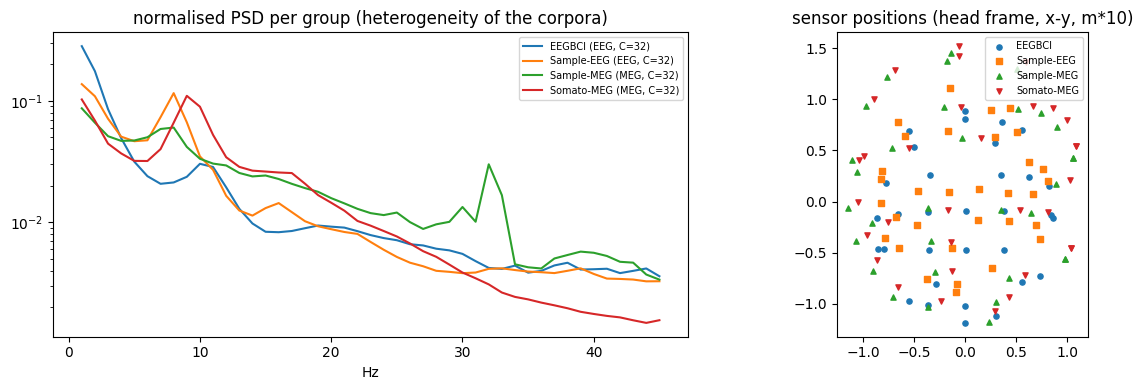

In [ ]:
# ---- sanity figure: mean power spectrum + sensor geometry per group (MNE Welch PSD on the training windows) ----
from mne.time_frequency import psd_array_welch
_w0 = build_world(0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, name in enumerate(GROUPS):
    X = _w0.raw[name]["train"][0][:200].numpy().astype(np.float64)
    psd, f = psd_array_welch(X, sfreq=cfg.FS, fmin=0.5, fmax=45, n_fft=128, verbose=False)
    ax[0].semilogy(f, psd.mean((0, 1)) / psd.mean((0, 1)).sum(), label=f"{name} ({SPECS[name]['mod']}, C={X.shape[1]})")
    p = _w0.L[name][:, :3].cpu().numpy(); ax[1].scatter(p[:, 0], p[:, 1], s=14, marker="os^v"[k], label=name)
ax[0].set_xlabel("Hz"); ax[0].set_title("normalised PSD per group (heterogeneity of the corpora)"); ax[0].legend(fontsize=7)
ax[1].set_title("sensor positions (head frame, x-y, m*10)"); ax[1].set_aspect("equal"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("neurogrape_data_overview.png", dpi=130); plt.show(); del _w0

## Stage 1: BrainTokenizer (BrainOmni)
Unchanged architecture: sensor encoder → SEANet temporal encoder → cross-attention backward solution (C' source queries) → 4-layer RVQ → cross-attention forward solution → SEANet decoder.
New: `train_tokenizer(world, mode)` supports `mode="focus"` (last third of training samples groups in proportion to their validation reconstruction error, same total budget). It is only used in the tokenizer ablation.
Tokenizer quality per group (PCC, codebook usage) is recorded for every seed so we can separate **representation quality** from **mixture weighting**.

In [ ]:
class RMSNorm(nn.Module):
    def __init__(s, d, eps=1e-6):
        super().__init__(); s.w = nn.Parameter(torch.ones(d)); s.eps = eps
    def forward(s, x): return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + s.eps) * s.w

class SensorEncoder(nn.Module):
    def __init__(s, D):
        super().__init__()
        s.pos = nn.Linear(6, D); s.type_emb = nn.Embedding(3, D)
        s.mlp = nn.Sequential(nn.Linear(D, D), nn.GELU(), nn.Linear(D, D)); s.norm = RMSNorm(D)
    def forward(s, L, S):                              # (C,6), (C,) -> (C,D)
        h = s.pos(L) + s.type_emb(S)
        return s.norm(h + s.mlp(h))

class ResUnit(nn.Module):
    def __init__(s, c, dil=1):
        super().__init__()
        s.net = nn.Sequential(nn.ELU(), nn.Conv1d(c, c, 3, padding=dil, dilation=dil), nn.ELU(), nn.Conv1d(c, c, 1))
    def forward(s, x): return x + s.net(x)

class SEANetEnc(nn.Module):                            # total stride 16
    def __init__(s, D):
        super().__init__()
        ch = [16, 32, 32, D, D]
        layers = [nn.Conv1d(1, ch[0], 7, padding=3)]
        for i in range(4):
            layers += [ResUnit(ch[i]), nn.ELU(), nn.Conv1d(ch[i], ch[i + 1], 4, stride=2, padding=1)]
        layers += [nn.ELU(), nn.Conv1d(D, D, 3, padding=1)]
        s.net = nn.Sequential(*layers)
    def forward(s, x): return s.net(x)

class SEANetDec(nn.Module):
    def __init__(s, D):
        super().__init__()
        ch = [D, D, 32, 32, 16]
        layers = [nn.Conv1d(D, D, 3, padding=1)]
        for i in range(4):
            layers += [nn.ELU(), nn.ConvTranspose1d(ch[i], ch[i + 1], 4, stride=2, padding=1), ResUnit(ch[i + 1])]
        layers += [nn.ELU(), nn.Conv1d(16, 1, 7, padding=3)]
        s.net = nn.Sequential(*layers)
    def forward(s, z): return s.net(z)

class RVQ(nn.Module):
    """Residual vector quantiser with EMA codebooks, data-dependent init and dead-code restarts."""
    def __init__(s, D, Kc, Nq, decay=0.99):
        super().__init__()
        s.Kc, s.Nq, s.decay = Kc, Nq, decay
        s.register_buffer("cb", torch.randn(Nq, Kc, D) * 0.1)
        s.register_buffer("ema_n", torch.ones(Nq, Kc)); s.register_buffer("ema_s", s.cb.clone())
        s.register_buffer("inited", torch.zeros(1))
    def forward(s, z):                                 # z: (N, D)
        res, q_out, idx, loss = z, 0, [], 0.0
        for i in range(s.Nq):
            if s.training and s.inited.item() == 0:
                s.cb[i] = res.detach()[torch.randperm(res.shape[0], device=z.device)[:s.Kc]]
                s.ema_s[i] = s.cb[i]
            cb = s.cb[i]
            d = res.pow(2).sum(1, keepdim=True) - 2 * res @ cb.t() + cb.pow(2).sum(1)[None]
            ind = d.argmin(1); q = cb[ind]
            if s.training:
                with torch.no_grad():
                    oh = F.one_hot(ind, s.Kc).float()
                    s.ema_n[i].mul_(s.decay).add_(oh.sum(0), alpha=1 - s.decay)
                    s.ema_s[i].mul_(s.decay).add_(oh.t() @ res.detach(), alpha=1 - s.decay)
                    n = s.ema_n[i].sum(); c = (s.ema_n[i] + 1e-5) / (n + s.Kc * 1e-5) * n
                    s.cb[i] = s.ema_s[i] / c[:, None]
                    dead = s.ema_n[i] < 0.03
                    if dead.any():
                        s.cb[i][dead] = res.detach()[torch.randint(0, res.shape[0], (int(dead.sum()),), device=z.device)]
                        s.ema_s[i][dead] = s.cb[i][dead]; s.ema_n[i][dead] = 1.0
            loss = loss + F.mse_loss(res, q.detach())       # commitment ||z_i - z_q^i||^2
            q_out = q_out + (res + (q - res).detach())
            res = res - q.detach(); idx.append(ind)
        if s.training: s.inited.fill_(1)
        return q_out, torch.stack(idx, -1), loss

class BrainTokenizer(nn.Module):
    def __init__(s, c):
        super().__init__()
        D = c.D; s.c = c
        s.sensor = SensorEncoder(D); s.enc = SEANetEnc(D); s.dec = SEANetDec(D)
        s.q_src = nn.Parameter(torch.randn(c.Cq, D) * 0.5)
        s.back = nn.MultiheadAttention(D, 4, batch_first=True); s.back_o = nn.Linear(D, D)
        s.fwd = nn.MultiheadAttention(D, 4, batch_first=True); s.fwd_o = nn.Linear(D, D)
        s.rvq = RVQ(D, c.Kc, c.Nq)
    @staticmethod
    def norm_x(x): return (x - x.mean(-1, keepdim=True)) / (x.std(-1, keepdim=True) + 1e-5)
    def sources(s, x, L, S):
        B, C, T = x.shape; W = T // 16
        zt = s.enc(x.reshape(B * C, 1, T)).view(B, C, -1, W).permute(0, 1, 3, 2)      # (B,C,W,D) temporal reps
        V = s.sensor(L, S)                                                             # (C,D)
        kv = (zt + V[None, :, None, :]).permute(0, 2, 1, 3).reshape(B * W, C, -1)      # K = Z_time + V_sensor
        val = zt.permute(0, 2, 1, 3).reshape(B * W, C, -1)                             # V = Z_time
        q = s.q_src[None].expand(B * W, -1, -1)
        o, _ = s.back(q, kv, val)
        return s.back_o(o).view(B, W, s.c.Cq, -1).permute(0, 2, 1, 3), V               # (B,C',W,D)
    def forward(s, x, L, S):
        x = s.norm_x(x); B, C, T = x.shape; W = T // 16
        zs, V = s.sources(x, L, S)
        qz, idx, lrvq = s.rvq(zs.reshape(-1, zs.shape[-1]))
        qz = qz.view(zs.shape)
        qk = qz.permute(0, 2, 1, 3).reshape(B * W, s.c.Cq, -1)
        qry = V[None].expand(B * W, -1, -1)
        o, _ = s.fwd(qry, qk, qk)                                                      # forward solution
        zh = s.fwd_o(o).view(B, W, C, -1).permute(0, 2, 3, 1).reshape(B * C, -1, W)
        xh = s.dec(zh).view(B, C, T)
        return x, xh, idx.view(B, s.c.Cq, W, s.c.Nq), lrvq
    @torch.no_grad()
    def encode(s, x, L, S):
        s.eval(); x = s.norm_x(x)
        zs, _ = s.sources(x, L, S); _, idx, _ = s.rvq(zs.reshape(-1, zs.shape[-1]))
        return idx.view(x.shape[0], s.c.Cq, -1, s.c.Nq)

def tokenizer_loss(x, xh, lrvq):
    l_time = (x - xh).abs().mean()
    win = torch.hann_window(64, device=x.device)
    A = torch.stft(x.reshape(-1, x.shape[-1]), 64, 16, window=win, return_complex=True)
    Ah = torch.stft(xh.reshape(-1, x.shape[-1]), 64, 16, window=win, return_complex=True)
    l_freq = (A.abs() - Ah.abs()).abs().mean() + 0.1 * (torch.angle(A) - torch.angle(Ah)).abs().mean()
    xc, xhc = x - x.mean(-1, keepdim=True), xh - xh.mean(-1, keepdim=True)
    pcc = (xc * xhc).sum(-1) / (xc.norm(dim=-1) * xhc.norm(dim=-1) + 1e-6)
    l_pcc = torch.exp(-pcc).mean()
    return l_time + l_freq + l_pcc + lrvq, dict(time=l_time.item(), freq=l_freq.item(), pcc=pcc.mean().item(), rvq=float(lrvq.detach()))

def sample_windows(w, name, split, n):
    X, y = w.raw[name][split]
    i = torch.randint(0, X.shape[0], (n,))
    return X[i].to(dev), y[i]

def _pcc(x, xh):
    xc, xhc = x - x.mean(-1, keepdim=True), xh - xh.mean(-1, keepdim=True)
    return ((xc * xhc).sum(-1) / (xc.norm(dim=-1) * xhc.norm(dim=-1) + 1e-6)).mean().item()

@torch.no_grad()
def recon_pcc(w, tok, split="test", n=64):
    tok.eval(); out = []
    for name in GROUPS:
        x, _ = sample_windows(w, name, split, n)
        x, xh, _, _ = tok(x, w.L[name], w.S[name])
        out.append(_pcc(x, xh))
    return np.array(out)

@torch.no_grad()
def tok_diagnostics(w, tok):
    tok.eval(); pcc, codes = [], []
    for name in GROUPS:
        x, _ = sample_windows(w, name, "test", 64)
        x, xh, idx, _ = tok(x, w.L[name], w.S[name])
        pcc.append(_pcc(x, xh))
        codes.append(float(np.mean([len(idx[..., i].unique()) / cfg.Kc for i in range(cfg.Nq)])))   # fraction of codebook used
    return dict(pcc=pcc, codes=codes)

def train_tokenizer(w, mode="rr"):
    """mode 'rr': round-robin over groups. 'focus': same, but the last third samples groups ~ val reconstruction error."""
    set_seed(w.seed)
    tok = BrainTokenizer(cfg).to(dev)
    opt = torch.optim.AdamW(tok.parameters(), lr=cfg.lr_tok, weight_decay=1e-4)
    switch, p = int(cfg.tok_steps * 2 / 3), None
    for step in range(cfg.tok_steps):
        if mode == "focus" and step == switch:
            q = np.clip(1 - recon_pcc(w, tok, "val", 32), 1e-3, None); p = q / q.sum()
        gi = step % K if p is None else int(np.random.choice(K, p=p))
        name = GROUPS[gi]
        tok.train()
        x, _ = sample_windows(w, name, "train", cfg.tok_bs)
        x, xh, _, lrvq = tok(x, w.L[name], w.S[name])
        loss, parts = tokenizer_loss(x, xh, lrvq)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(tok.parameters(), 1.0); opt.step()
    diag = tok_diagnostics(w, tok)
    diag["focus_p"] = None if p is None else [float(v) for v in p]
    return tok, diag

### Tokenise every window (the shared neural-token vocabulary)
After this, the backbone no longer sees channels or devices: every window is a `(C', W, 4)` grid of integer tokens, whatever the group.
Training tokens are stored in a padded tensor `(K, N_max, C', W, 4)` with per-group sizes `NSZ`, because groups now have **different sizes**.
We also compute a **context-free token-entropy floor** per group: the masked-token loss of a model that only knows each token position's marginal distribution.
It measures how much of a group's loss is just vocabulary entropy from the tokenizer (representation), as opposed to what the transformer learns from context.

In [ ]:
def tokenise_world(w, tok):
    def enc(name, split):
        X, _ = w.raw[name][split]
        return torch.cat([tok.encode(X[i:i + 64].to(dev), w.L[name], w.S[name]) for i in range(0, X.shape[0], 64)])
    tr = [enc(n, "train") for n in GROUPS]
    w.NSZ = torch.tensor([t.shape[0] for t in tr], device=dev)
    w.TR = torch.zeros(K, int(w.NSZ.max()), *tr[0].shape[1:], dtype=torch.long, device=dev)
    for k in range(K): w.TR[k, :tr[k].shape[0]] = tr[k]
    w.VA = torch.stack([enc(n, "val") for n in GROUPS])
    w.TE = torch.stack([enc(n, "test") for n in GROUPS])
    w.YTR = [w.raw[n]["train"][1].to(dev) for n in GROUPS]                     # list: sizes differ
    w.YVA = torch.stack([w.raw[n]["val"][1] for n in GROUPS]).to(dev)
    w.YTE = torch.stack([w.raw[n]["test"][1] for n in GROUPS]).to(dev)
    w.POS_IDX = [[(w.YVA[k, :, col] == 1).nonzero().squeeze(-1) for k in range(K)] for (_, col, _) in TASKS]
    # fixed masked copies of val/test so every model in this seed is scored on identical inputs
    set_seed(999 + w.seed)
    w.EVAL = {sp: [make_masked(tk[k]) for k in range(K)] for sp, tk in [("val", w.VA), ("test", w.TE)]}
    return w

## Stage 2: Criss-Cross Transformer backbone with masked-token prediction
Unchanged: half of the hidden dimension attends across the C' source axis, half across time (RoPE). 50% masking (80% `[MASK]`, 20% random), cross-entropy summed over the 4 RVQ levels.

In [ ]:
def apply_rope(x, base=10000.0):                       # x: (N, H, L, dh)
    L, dh = x.shape[-2], x.shape[-1]; half = dh // 2
    ang = torch.arange(L, device=x.device)[:, None] * (1.0 / base ** (torch.arange(half, device=x.device) / half))[None]
    cos, sin = ang.cos(), ang.sin()
    x1, x2 = x[..., :half], x[..., half:]
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1)

class CrissCross(nn.Module):
    def __init__(s, D, H):
        super().__init__()
        s.H = H // 2; s.dh = (D // 2) // s.H
        s.n1, s.n2 = RMSNorm(D), RMSNorm(D)
        s.qkv_s = nn.Linear(D // 2, 3 * (D // 2)); s.qkv_t = nn.Linear(D // 2, 3 * (D // 2))
        s.o = nn.Linear(D, D)
        s.mlp = nn.Sequential(nn.Linear(D, 4 * D), nn.GELU(), nn.Linear(4 * D, D))
    def _attn(s, h, qkv, spatial):
        B, C, W, d = h.shape
        q, k, v = qkv(h).chunk(3, -1)
        if spatial: f = lambda t: t.permute(0, 2, 1, 3).reshape(B * W, C, s.H, s.dh).transpose(1, 2)
        else:       f = lambda t: t.reshape(B * C, W, s.H, s.dh).transpose(1, 2)
        q, k, v = f(q), f(k), f(v)
        if not spatial: q, k = apply_rope(q), apply_rope(k)
        o = F.scaled_dot_product_attention(q, k, v).transpose(1, 2)
        return o.reshape(B, W, C, d).permute(0, 2, 1, 3) if spatial else o.reshape(B, C, W, d)
    def forward(s, x):
        hs, ht = s.n1(x).chunk(2, -1)
        x = x + s.o(torch.cat([s._attn(hs, s.qkv_s, True), s._attn(ht, s.qkv_t, False)], -1))
        return x + s.mlp(s.n2(x))

class Backbone(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.emb = nn.ModuleList([nn.Embedding(c.Kc + 1, c.Dm) for _ in range(c.Nq)])   # index Kc = [MASK]
        s.pos = nn.Parameter(torch.randn(c.Cq, c.Dm) * 0.02)
        s.blocks = nn.ModuleList([CrissCross(c.Dm, c.heads) for _ in range(c.layers)])
        s.norm = RMSNorm(c.Dm); s.heads = nn.Linear(c.Dm, c.Kc * c.Nq)
    def encode(s, inp):                                # (B,C',W,Nq) -> (B,C',W,Dm)
        x = sum(e(inp[..., i]) for i, e in enumerate(s.emb)) + s.pos[None, :, None, :]
        for b in s.blocks: x = b(x)
        return s.norm(x)
    def forward(s, inp):
        h = s.encode(inp); return s.heads(h).view(*h.shape[:3], s.c.Nq, s.c.Kc)

def make_masked(tokens):
    """50% masking; of masked positions 80% -> [MASK], 20% -> random tokens."""
    m = torch.rand(tokens.shape[:3], device=tokens.device) < cfg.mask_ratio
    r = torch.rand(tokens.shape[:3], device=tokens.device)
    inp = tokens.clone(); inp[m & (r < 0.8)] = cfg.Kc
    rnd = torch.randint(0, cfg.Kc, tokens.shape, device=tokens.device)
    return torch.where((m & (r >= 0.8))[..., None], rnd, inp), m

def token_loss(logits, tokens):                        # -> (B,C',W): CE summed over RVQ levels
    return F.cross_entropy(logits.reshape(-1, cfg.Kc), tokens.reshape(-1), reduction="none").view(tokens.shape).sum(-1)

@torch.no_grad()
def group_losses(w, model, split="test", ref=None):
    """Mean masked-token loss per group (and excess over the reference model)."""
    model.eval(); tk = w.TE if split == "test" else w.VA; out, exc = [], []
    for k in range(K):
        inp, m = w.EVAL[split][k]; l = token_loss(model(inp), tk[k])
        out.append((l * m).sum().item() / m.sum().item())
        if ref is not None:
            lr = token_loss(ref(inp), tk[k]); exc.append(((l - lr).clamp(min=0) * m).sum().item() / m.sum().item())
    return np.array(out), (np.array(exc) if ref is not None else None)

@torch.no_grad()
def unigram_floor(w):
    """Context-free masked-token loss per group: each (source, RVQ level) token predicted from its marginal distribution only."""
    out = []
    for k in range(K):
        tr = w.TR[k, :int(w.NSZ[k])]                                   # (N,C',W,Nq)
        logp = torch.zeros(cfg.Cq, cfg.Nq, cfg.Kc, device=dev)
        for c in range(cfg.Cq):
            for q in range(cfg.Nq):
                cnt = torch.bincount(tr[:, c, :, q].reshape(-1), minlength=cfg.Kc).float() + 0.5
                logp[c, q] = torch.log(cnt / cnt.sum())
        te = w.TE[k]; nll = torch.zeros(te.shape[:3], device=dev)
        for c in range(cfg.Cq):
            for q in range(cfg.Nq):
                nll[:, c, :] -= logp[c, q][te[:, c, :, q]]
        m = w.EVAL["test"][k][1]
        out.append(((nll * m).sum() / m.sum()).item())
    return np.array(out)

## Stage 3-5: Neuro-GRAPE training engine
One function covers every method (unchanged logic from v1, now operating on a per-seed `world`):

* **fixed mixture** (Uniform / EEG-heavy / MEG-heavy / learned α): windows are sampled per group with probabilities α.
* **adaptive proxy run** (`doremi`, `grape`, `neurogrape`): equal batch per group, loss `Σ_k α_k ℓ_k`, multiplicative weight updates.

  * **DoReMi excess loss** `λ_k = Σ max(ℓ_θ − ℓ_ref, 0) / #masked tokens` → `α̂_k = α_k · exp(η_dro · λ_k)`
  * **GRAPE task RoI** via cosine gradient alignment: `z_n ∝ z_n·exp(−η_z·roi_n)` (lagging tasks up-weighted), `α̂_k = α_k·exp(η_α Σ_n z_n A_nk)`

The learned mixture is α averaged over the proxy run. Target tasks use the **val** split only; the test split never touches the mixture.
**Fairness:** for a given seed, all methods share data, tokenizer, backbone init seed, step count, batch size, LR schedule and eval masks. Only the mixture differs.

In [ ]:
def flat_grad(loss, params, retain=True):
    gs = torch.autograd.grad(loss, params, retain_graph=retain, allow_unused=True)
    return torch.cat([(g if g is not None else torch.zeros_like(p)).reshape(-1) for g, p in zip(gs, params)])

def task_batch(w, n):
    wts = torch.tensor(TASKS[n][2], dtype=torch.float)
    gids = torch.multinomial(wts, cfg.task_bs, replacement=True); toks = []
    for g in gids.tolist():
        pi = w.POS_IDX[n][g]
        j = pi[torch.randint(0, len(pi), (1,))].item() if len(pi) > 0 else int(torch.randint(0, w.VA.shape[1], (1,)))
        toks.append(w.VA[g, j])
    return torch.stack(toks)

def smooth_norm(a, c=cfg.smooth_c):
    a = a / a.sum(); return (1 - c) * a + c / len(a)

def train_backbone(w, name, steps, alpha=None, method=None, ref=None, seed=0, verbose=False):
    set_seed(seed)
    model = Backbone(cfg).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr_bb, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 30) * 0.5 * (1 + math.cos(math.pi * s / steps)))
    params_al = list(model.blocks[-1].parameters()) + list(model.heads.parameters())
    a = torch.full((K,), 1.0 / K) if alpha is None else torch.tensor(alpha, dtype=torch.float)
    z = torch.full((N_TASK,), 1.0 / N_TASK)
    traj_a, traj_z = [], []
    use_dro, use_grape = method in ("doremi", "neurogrape"), method in ("grape", "neurogrape")
    t0 = time.time()
    for step in range(steps):
        model.train()
        if method is None:                                     # fixed mixture: sample group ~ alpha
            gid = torch.multinomial(a, cfg.bg * K, replacement=True)
        else:                                                  # proxy: equal batch per group, loss weighted by alpha
            gid = torch.arange(K).repeat_interleave(cfg.bg)
        gid_d = gid.to(dev)
        idx = (torch.rand(len(gid), device=dev) * w.NSZ[gid_d]).long()     # per-group sizes differ
        tokens = w.TR[gid_d, idx]
        inp, m = make_masked(tokens)
        l = token_loss(model(inp), tokens)                     # (B,C',W)
        lk = [((l[gid_d == k] * m[gid_d == k]).sum() / m[gid_d == k].sum().clamp(min=1)) if (gid_d == k).any() else l.sum() * 0 for k in range(K)]
        loss = sum(a[k].item() * lk[k] for k in range(K)) if method is not None else (l * m).sum() / m.sum()

        if method is not None and step >= cfg.warmup_frac * steps:
            a_hat = a.clone()
            if use_dro:                                        # DoReMi excess loss against the reference model
                with torch.no_grad():
                    ex = (l.detach() - token_loss(ref(inp), tokens)).clamp(min=0) * m
                    lam = torch.tensor([ex[gid_d == k].sum().item() / max(m[gid_d == k].sum().item(), 1) for k in range(K)])
                a_hat = a_hat * torch.exp(cfg.eta_dro * lam)
            if use_grape and step % cfg.align_every == 0:      # GRAPE gradient alignment
                G = torch.stack([flat_grad(lk[k], params_al) for k in range(K)])           # g_k
                H = []
                for n in range(N_TASK):
                    tt = task_batch(w, n); ti, tm = make_masked(tt)
                    ln = (token_loss(model(ti), tt) * tm).sum() / tm.sum()
                    H.append(flat_grad(ln, params_al, retain=False) / ln.item())          # grad log l_n
                H = torch.stack(H)
                A = (H @ G.t()) / (H.norm(dim=1)[:, None] * G.norm(dim=1)[None] + 1e-8)   # cosine alignment (N,K)
                A = A.cpu()
                roi = A @ a
                z = z * torch.exp(-cfg.eta_z * roi); z = z / z.sum()                       # upweight lagging tasks
                a_hat = a_hat * torch.exp(cfg.eta_alpha * (z @ A))                        # upweight domains that help them
            a = smooth_norm(a_hat)
        traj_a.append(a.clone().numpy()); traj_z.append(z.clone().numpy())
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        if verbose and (step % max(1, steps // 5) == 0 or step == steps - 1):
            msg = f"[{name}] step {step:4d}  loss {loss.item():.3f}"
            if method is not None: msg += "  alpha=" + np.array2string(a.numpy(), precision=3)
            print(msg + f"  ({time.time()-t0:.0f}s)")
    return model, dict(alpha=np.array(traj_a), z=np.array(traj_z))

## Stage 6: downstream evaluation (per group)
Token features from the frozen backbone are average-pooled over time, flattened to `(B, C'·D)` and fed to a 2-layer MLP head predicting the three label columns. The head is trained on `n_finetune` labelled windows per group (the same number for every group) and scored on each group's **test** split separately, so we can report **average** and **worst-group** accuracy.

v3: labels equal to `-1` (not available in that dataset) are masked out of the loss and the metric; a group's accuracy is the mean over the columns it has. On real data the metric is **balanced accuracy** (mean of per-class recall; chance = 0.5) and the BCE uses class-balancing weights, because event/seizure labels are imbalanced.

In [ ]:
BALANCED_ACC = (DATA_SOURCE == "mne_real")             # real labels are imbalanced -> report balanced accuracy (simulated labels are balanced)

@torch.no_grad()
def features(model, tokens):                           # tokens (N,C',W,4) clean -> (N, C'*Dm)
    model.eval(); out = []
    for i in range(0, tokens.shape[0], 128):
        h = model.encode(tokens[i:i + 128]); out.append(h.mean(2).flatten(1))   # average pool over W
    return torch.cat(out)

def _acc(pred, y):
    """Accuracy (sim) / balanced accuracy (real) over the windows that carry a label (y >= 0); NaN if undefined."""
    m = y >= 0
    if int(m.sum()) == 0: return float("nan")
    p, t = pred[m], y[m]
    if not BALANCED_ACC: return (p == t).float().mean().item()
    rec = [(p[t == c] == c).float().mean().item() for c in (0, 1) if bool((t == c).any())]
    return float(np.mean(rec)) if len(rec) == 2 else float("nan")

def downstream(w, model, seed=0, steps=300):
    set_seed(seed)
    n = min(cfg.n_finetune, int(w.NSZ.min()))
    Ftr = torch.cat([features(model, w.TR[k, :n]) for k in range(K)]); Ytr = torch.cat([w.YTR[k][:n] for k in range(K)])
    M = (Ytr >= 0).float(); Yf = Ytr.clamp(min=0).float()                       # -1 = label not available in that group
    pos = (Yf * M).sum(0); neg = M.sum(0) - pos
    pw = (neg.clamp(min=1) / pos.clamp(min=1)) if BALANCED_ACC else torch.ones(N_COL, device=dev)
    mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-5
    head = nn.Sequential(nn.Linear(Ftr.shape[1], 128), nn.GELU(), nn.Linear(128, N_COL)).to(dev)
    o = torch.optim.Adam(head.parameters(), lr=2e-3, weight_decay=1e-3)
    for _ in range(steps):
        i = torch.randint(0, Ftr.shape[0], (128,), device=dev)
        l = F.binary_cross_entropy_with_logits(head((Ftr[i] - mu) / sd), Yf[i], pos_weight=pw, reduction="none")
        loss = (l * M[i]).sum() / M[i].sum().clamp(min=1)
        o.zero_grad(); loss.backward(); o.step()
    acc = np.full((K, N_COL), np.nan)
    with torch.no_grad():
        for k in range(K):
            pred = (head((features(model, w.TE[k]) - mu) / sd) > 0).long()
            acc[k] = [_acc(pred[:, c], w.YTE[k][:, c]) for c in range(N_COL)]
    return acc                                          # (K, N_COL); NaN where a group has no such label

## One full experiment for one seed
`run_seed(seed)` does the entire pipeline for a seed: build world → tokenizer → tokens → **reference/Uniform** model → **three proxy runs** (DoReMi, GRAPE, Neuro-GRAPE) → final retraining on every learned mixture → evaluation.
Results are checkpointed to `results/<scenario>_<tokenizer-mode>_seed<k>.json`, so if Colab disconnects, just re-run the notebook: finished seeds are loaded from disk.

For the first `SWEEP_SEEDS` seeds it also runs the **α-sweep control**: retrain with the weight on the *hardest group* (chosen on the val split from the Uniform model) set to 0.10 / 0.25 / 0.40 / 0.55 / 0.70, other groups sharing the rest equally. This isolates how much *weighting alone* can move that group's loss.

In [ ]:
def run_seed(seed, tok_mode="rr", do_sweep=False):
    extra = INCLUDE_EXTRA_FIXED and tok_mode == "rr"
    path = os.path.join(RESULT_DIR, f"{TAG}_{tok_mode}_seed{seed}.json")
    if os.path.exists(path):
        d = json.load(open(path))
        if (not do_sweep) or d.get("sweep"):
            print(f"[seed {seed} | tok={tok_mode}] loaded from {path}"); return d
    t0 = time.time(); lg = lambda msg: print(f"[seed {seed} | tok={tok_mode}] {msg}  ({time.time()-t0:.0f}s)")
    w = build_world(seed)
    tok, tokdiag = train_tokenizer(w, tok_mode); tokenise_world(w, tok)
    lg("tokenizer PCC per group " + str(dict(zip(GROUPS, np.round(tokdiag["pcc"], 3)))))
    floor = unigram_floor(w)

    uni = FIXED_MIXTURES["Uniform"]
    ref, _ = train_backbone(w, "ref/uniform", cfg.bb_steps, alpha=uni, seed=seed)
    ref.eval()
    for p in ref.parameters(): p.requires_grad_(False)
    lg("reference (Uniform) trained")

    mix, traj = {"Uniform": np.array(uni)}, {}
    for method, label in [("doremi", "DoReMi"), ("grape", "GRAPE"), ("neurogrape", "Neuro-GRAPE")]:
        _, info = train_backbone(w, f"proxy/{method}", cfg.bb_steps, method=method, ref=ref, seed=seed)
        mix[label] = info["alpha"].mean(0); traj[label] = info["alpha"][::10].tolist()
        if method == "neurogrape": traj["task_weights"] = info["z"][::10].tolist()
        lg(f"proxy {label:11s} learned alpha = {np.round(mix[label], 3)}")
    if extra:
        mix["EEG-heavy"] = np.array(FIXED_MIXTURES["EEG-heavy"]); mix["MEG-heavy"] = np.array(FIXED_MIXTURES["MEG-heavy"])

    models = {"Uniform": ref}
    for name in [m for m in ORDER if m in mix and m != "Uniform"]:
        models[name], _ = train_backbone(w, f"final/{name}", cfg.bb_steps, alpha=mix[name], seed=seed)
    lg("final models trained")

    res = {}
    for name in [m for m in ORDER if m in models]:
        loss_g, exc_g = group_losses(w, models[name], "test", ref); acc = downstream(w, models[name], seed)
        res[name] = dict(alpha=[float(v) for v in mix[name]], loss=loss_g.tolist(), exc=exc_g.tolist(),
                         acc=np.nanmean(acc, 1).tolist(), acc_task=acc.tolist())
    lg("evaluated: " + "  ".join(f"{m}: acc {np.mean(r['acc']):.3f}/worst {np.min(r['acc']):.3f}" for m, r in res.items()))

    sweep = None
    if do_sweep:
        val_l, _ = group_losses(w, ref, "val"); h = int(val_l.argmax())
        sweep = dict(hardest=h, group=GROUPS[h], points=[])
        for wt in SWEEP_W:
            if abs(wt - 0.25) < 1e-9: mdl = ref
            else:
                a = [(1 - wt) / (K - 1)] * K; a[h] = wt
                mdl, _ = train_backbone(w, f"sweep/{wt}", cfg.bb_steps, alpha=a, seed=seed)
            l, _ = group_losses(w, mdl, "test"); acc = np.nanmean(downstream(w, mdl, seed), 1)
            sweep["points"].append(dict(w=wt, loss=l.tolist(), acc=acc.tolist()))
        lg(f"alpha-sweep on hardest group ({GROUPS[h]}) done")

    out = dict(seed=seed, tok_mode=tok_mode, scenario=SCENARIO, data_source=DATA_SOURCE, provenance=PROV, tok=tokdiag, floor=floor.tolist(), methods=res, traj=traj, sweep=sweep)
    json.dump(out, open(path, "w"))
    return out

## Main experiment: all methods × all seeds
Prints one line per stage. With `QUICK=False` and 5 seeds this is the long cell: run it on a **GPU runtime** (Runtime → Change runtime type → T4). Already-finished seeds are skipped.

In [ ]:
RES = {}
for s in range(N_SEEDS):
    RES[s] = run_seed(s, "rr", do_sweep=RUN_ALPHA_SWEEP and s < SWEEP_SEEDS)
print("\nfinished seeds:", sorted(RES))

[seed 0 | tok=rr] tokenizer PCC per group {'EEGBCI': np.float64(0.421), 'Sample-EEG': np.float64(0.26), 'Sample-MEG': np.float64(0.136), 'Somato-MEG': np.float64(0.135)}  (31s)
[seed 0 | tok=rr] reference (Uniform) trained  (42s)
[seed 0 | tok=rr] proxy DoReMi      learned alpha = [0.269 0.281 0.256 0.194]  (57s)
[seed 0 | tok=rr] proxy GRAPE       learned alpha = [0.566 0.14  0.16  0.134]  (74s)
[seed 0 | tok=rr] proxy Neuro-GRAPE learned alpha = [0.281 0.272 0.246 0.2  ]  (94s)
[seed 0 | tok=rr] final models trained  (147s)
[seed 0 | tok=rr] evaluated: Uniform: acc 0.588/worst 0.486  EEG-heavy: acc 0.585/worst 0.470  MEG-heavy: acc 0.575/worst 0.499  DoReMi: acc 0.565/worst 0.501  GRAPE: acc 0.580/worst 0.529  Neuro-GRAPE: acc 0.582/worst 0.510  (151s)
[seed 0 | tok=rr] alpha-sweep on hardest group (Sample-MEG) done  (197s)
[seed 1 | tok=rr] tokenizer PCC per group {'EEGBCI': np.float64(0.339), 'Sample-EEG': np.float64(0.355), 'Sample-MEG': np.float64(0.196), 'Somato-MEG': np.float64

## Results across seeds
Primary hypothesis (slide 2): *Neuro-GRAPE improves worst-group performance while maintaining average performance versus fixed mixtures.*
All tables are mean ± std over seeds (`ddof=1`). "Worst-group loss" is the max over groups of the masked-token test loss; "worst-group accuracy" is the min over groups of the mean downstream accuracy (3 events).

In [ ]:
import pandas as pd
from scipy import stats

SEEDS = sorted(RES); S_ = len(SEEDS)
METHODS = [m for m in ORDER if m in RES[SEEDS[0]]["methods"]]
def stack(key, store=RES): return np.array([[store[s]["methods"][m][key] for m in METHODS] for s in SEEDS])   # (S,M,K)
LOSS, ACC, ALPHA = stack("loss"), stack("acc"), stack("alpha")
MET = dict(mean_acc=ACC.mean(2), worst_acc=ACC.min(2), mean_loss=LOSS.mean(2), worst_loss=LOSS.max(2))      # each (S,M)
sd = lambda a, ax=0: a.std(ax, ddof=1) if a.shape[ax] > 1 else np.zeros(a.shape[1 - ax] if a.ndim == 2 else ())
pm = lambda m, s, d=3: f"{m:.{d}f} ± {s:.{d}f}"

print("Data source:", DATA_SOURCE, " | ", ", ".join(f"{g} [{PROV[g]['source']}]" for g in GROUPS))
print(f"Scenario '{SCENARIO}', {S_} seeds ({SEEDS}), methods: {METHODS}\n")
tab = pd.DataFrame({
    "avg acc ↑":          [pm(MET["mean_acc"][:, j].mean(),  sd(MET["mean_acc"])[j])  for j in range(len(METHODS))],
    "worst-group acc ↑":  [pm(MET["worst_acc"][:, j].mean(), sd(MET["worst_acc"])[j]) for j in range(len(METHODS))],
    "avg loss ↓":         [pm(MET["mean_loss"][:, j].mean(), sd(MET["mean_loss"])[j]) for j in range(len(METHODS))],
    "worst-group loss ↓": [pm(MET["worst_loss"][:, j].mean(), sd(MET["worst_loss"])[j]) for j in range(len(METHODS))],
}, index=METHODS)
show(tab)

print("\nPer-group test masked-token loss (↓), mean ± std over seeds")
show(pd.DataFrame([[pm(LOSS[:, j, k].mean(), sd(LOSS[:, j, :])[k]) for k in range(K)] for j in range(len(METHODS))], index=METHODS, columns=GROUPS))
print("\nPer-group downstream accuracy (↑), mean ± std over seeds")
show(pd.DataFrame([[pm(ACC[:, j, k].mean(), sd(ACC[:, j, :])[k]) for k in range(K)] for j in range(len(METHODS))], index=METHODS, columns=GROUPS))
print("\nLearned / fixed mixture weights α, mean ± std over seeds")
show(pd.DataFrame([[pm(ALPHA[:, j, k].mean(), sd(ALPHA[:, j, :])[k]) for k in range(K)] for j in range(len(METHODS))], index=METHODS, columns=GROUPS))

Data source: mne_real  |  EEGBCI [REAL (eegbci)], Sample-EEG [REAL (sample)], Sample-MEG [REAL (sample)], Somato-MEG [REAL (somato)]
Scenario 'hetero', 5 seeds ([0, 1, 2, 3, 4]), methods: ['Uniform', 'EEG-heavy', 'MEG-heavy', 'DoReMi', 'GRAPE', 'Neuro-GRAPE']



,avg acc ↑,worst-group acc ↑,avg loss ↓,worst-group loss ↓
Uniform,0.595 ± 0.016,0.510 ± 0.034,11.617 ± 0.360,12.076 ± 0.667
EEG-heavy,0.594 ± 0.026,0.536 ± 0.040,11.671 ± 0.398,12.302 ± 0.788
MEG-heavy,0.600 ± 0.016,0.520 ± 0.042,11.706 ± 0.408,12.204 ± 0.688
DoReMi,0.597 ± 0.025,0.538 ± 0.034,11.618 ± 0.377,12.116 ± 0.710
GRAPE,0.600 ± 0.022,0.535 ± 0.022,11.643 ± 0.375,12.174 ± 0.728
Neuro-GRAPE,0.594 ± 0.021,0.526 ± 0.015,11.617 ± 0.376,12.111 ± 0.703



Per-group test masked-token loss (↓), mean ± std over seeds


,EEGBCI,Sample-EEG,Sample-MEG,Somato-MEG
Uniform,10.871 ± 0.585,11.896 ± 0.632,12.029 ± 0.702,11.671 ± 0.567
EEG-heavy,10.736 ± 0.558,11.789 ± 0.632,12.302 ± 0.788,11.856 ± 0.613
MEG-heavy,11.198 ± 0.544,12.175 ± 0.714,11.875 ± 0.713,11.574 ± 0.595
DoReMi,10.822 ± 0.569,11.874 ± 0.610,12.056 ± 0.758,11.719 ± 0.610
GRAPE,10.827 ± 0.758,11.887 ± 0.617,12.130 ± 0.762,11.730 ± 0.667
Neuro-GRAPE,10.829 ± 0.569,11.880 ± 0.615,12.052 ± 0.750,11.708 ± 0.596



Per-group downstream accuracy (↑), mean ± std over seeds


,EEGBCI,Sample-EEG,Sample-MEG,Somato-MEG
Uniform,0.595 ± 0.047,0.627 ± 0.035,0.521 ± 0.044,0.636 ± 0.033
EEG-heavy,0.599 ± 0.037,0.606 ± 0.038,0.539 ± 0.044,0.633 ± 0.030
MEG-heavy,0.610 ± 0.042,0.622 ± 0.016,0.520 ± 0.042,0.646 ± 0.040
DoReMi,0.586 ± 0.048,0.612 ± 0.040,0.549 ± 0.036,0.643 ± 0.044
GRAPE,0.607 ± 0.063,0.625 ± 0.019,0.539 ± 0.027,0.629 ± 0.045
Neuro-GRAPE,0.595 ± 0.047,0.607 ± 0.039,0.532 ± 0.020,0.643 ± 0.047



Learned / fixed mixture weights α, mean ± std over seeds


,EEGBCI,Sample-EEG,Sample-MEG,Somato-MEG
Uniform,0.250 ± 0.000,0.250 ± 0.000,0.250 ± 0.000,0.250 ± 0.000
EEG-heavy,0.375 ± 0.000,0.375 ± 0.000,0.125 ± 0.000,0.125 ± 0.000
MEG-heavy,0.125 ± 0.000,0.125 ± 0.000,0.375 ± 0.000,0.375 ± 0.000
DoReMi,0.289 ± 0.034,0.263 ± 0.058,0.242 ± 0.035,0.206 ± 0.029
GRAPE,0.361 ± 0.169,0.221 ± 0.075,0.182 ± 0.037,0.236 ± 0.102
Neuro-GRAPE,0.287 ± 0.022,0.256 ± 0.050,0.238 ± 0.029,0.219 ± 0.020


### Paired statistics: Neuro-GRAPE vs every other method
Because every method shares data, tokenizer and init within a seed, we compare **per-seed paired differences** (positive = Neuro-GRAPE better). We report the mean difference, 95% t-interval, two-sided paired-t p-value, and the number of seeds Neuro-GRAPE wins.
With only a handful of seeds the intervals are wide; treat p-values as a guide, and prefer "consistent across seeds + CI excludes 0" over a single p < 0.05.
The **average-performance non-inferiority** check uses a one-sided 95% bound with margins of 2% relative loss and 1 accuracy point.

In [ ]:
def paired_stats(d):
    d = np.asarray(d, float); n = len(d); m = d.mean()
    s_ = d.std(ddof=1) if n > 1 else np.nan
    if n > 1 and s_ > 0:
        se = s_ / np.sqrt(n); lo, hi = m - stats.t.ppf(0.975, n - 1) * se, m + stats.t.ppf(0.975, n - 1) * se
        p = stats.ttest_1samp(d, 0.0).pvalue; lo1 = m - stats.t.ppf(0.95, n - 1) * se
    else: lo = hi = p = lo1 = np.nan
    return dict(mean=m, sd=s_, lo=lo, hi=hi, p=p, lo1=lo1, wins=int((d > 0).sum()), n=n)

if "Neuro-GRAPE" not in METHODS: raise RuntimeError("Neuro-GRAPE results missing")
iNG = METHODS.index("Neuro-GRAPE")
def diffs(metric, base, relative=False):                 # positive = Neuro-GRAPE better
    v = MET[metric]; j = METHODS.index(base); d = v[:, iNG] - v[:, j]
    if metric.endswith("loss"): d = -d
    return d / v[:, j] if relative else d

LABEL = dict(worst_acc="worst-group acc", mean_acc="avg acc", worst_loss="worst-group loss", mean_loss="avg loss")
def call(st):
    if np.isnan(st["lo"]): return "n/a (need ≥2 seeds with variance)"
    return "BETTER" if st["lo"] > 0 else ("WORSE" if st["hi"] < 0 else "no clear diff")

rows = []
for b in [m for m in METHODS if m != "Neuro-GRAPE"]:
    for metric in ["worst_acc", "mean_acc", "worst_loss", "mean_loss"]:
        st = paired_stats(diffs(metric, b))
        rows.append({"vs": b, "metric": LABEL[metric], "Δ (NG better > 0)": f"{st['mean']:+.4f}",
                     "95% CI": f"[{st['lo']:+.4f}, {st['hi']:+.4f}]", "p": f"{st['p']:.3f}", "NG wins": f"{st['wins']}/{st['n']}", "verdict": call(st)})
show(pd.DataFrame(rows).set_index(["vs", "metric"]))

print("\n=== Hypothesis check (simulation-based evidence only) ===")
for b in [m for m in METHODS if m != "Neuro-GRAPE"]:
    wa, wl = paired_stats(diffs("worst_acc", b)), paired_stats(diffs("worst_loss", b))
    na = paired_stats(diffs("mean_acc", b)); nl = paired_stats(diffs("mean_loss", b, relative=True))
    ok_avg = (na["lo1"] > -0.01) and (nl["lo1"] > -0.02)
    imp = "improved" if (wa["lo"] > 0 or wl["lo"] > 0) else ("point-estimate better, CI includes 0" if (wa["mean"] > 0 or wl["mean"] > 0) else "not improved")
    print(f"vs {b:10s}: worst-group {imp:38s} | average non-inferior: {ok_avg if not np.isnan(na['lo1']) else 'n/a'}")

Δ (NG better > 0)              95% CI      p  \
vs        metric                                                          
Uniform   worst-group acc            +0.0164  [-0.0099, +0.0427]  0.158   
          avg acc                    -0.0008  [-0.0193, +0.0176]  0.905   
          worst-group loss           -0.0352  [-0.0905, +0.0201]  0.152   
          avg loss                   -0.0005  [-0.0313, +0.0304]  0.969   
EEG-heavy worst-group acc            -0.0095  [-0.0448, +0.0259]  0.499   
          avg acc                    -0.0002  [-0.0197, +0.0193]  0.979   
          worst-group loss           +0.1908  [+0.0442, +0.3373]  0.022   
          avg loss                   +0.0538  [+0.0258, +0.0818]  0.006   
MEG-heavy worst-group acc            +0.0058  [-0.0333, +0.0450]  0.700   
          avg acc                    -0.0056  [-0.0248, +0.0136]  0.462   
          worst-group loss           +0.0932  [-0.0896, +0.2759]  0.230   
          avg loss                   +0.0885  [+0.0321, +0.1449]  0.012   
DoReMi    worst-group acc            -0.0116  [-0.0450, +0.0218]  0.389   
          avg acc                    -0.0033  [-0.0313, +0.0247]  0.759   
          worst-group loss           +0.0048  [-0.0180, +0.0276]  0.591   
          avg loss                   +0.0004  [-0.0084, +0.0093]  0.897   
GRAPE     worst-group acc            -0.0092  [-0.0432, +0.0247]  0.492   
          avg acc                    -0.0057  [-0.0181, +0.0066]  0.266   
          worst-group loss           +0.0632  [+0.0108, +0.1156]  0.029   
          avg loss                   +0.0263  [-0.0544, +0.1069]  0.417   

                           NG wins        verdict  
vs        metric                                   
Uniform   worst-group acc      4/5  no clear diff  
          avg acc              2/5  no clear diff  
          worst-group loss     0/5  no clear diff  
          avg loss             2/5  no clear diff  
EEG-heavy worst-group acc      1/5  no clear diff  
          avg acc              2/5  no clear diff  
          worst-group loss     5/5         BETTER  
          avg loss             5/5         BETTER  
MEG-heavy worst-group acc      3/5  no clear diff  
          avg acc              2/5  no clear diff  
          worst-group loss     4/5  no clear diff  
          avg loss             5/5         BETTER  
DoReMi    worst-group acc      3/5  no clear diff  
          avg acc              2/5  no clear diff  
          worst-group loss     2/5  no clear diff  
          avg loss             3/5  no clear diff  
GRAPE     worst-group acc      2/5  no clear diff  
          avg acc              2/5  no clear diff  
          worst-group loss     5/5         BETTER  
          avg loss             3/5  no clear diff


=== Hypothesis check (simulation-based evidence only) ===
vs Uniform   : worst-group point-estimate better, CI includes 0   | average non-inferior: False
vs EEG-heavy : worst-group improved                               | average non-inferior: False
vs MEG-heavy : worst-group point-estimate better, CI includes 0   | average non-inferior: False
vs DoReMi    : worst-group point-estimate better, CI includes 0   | average non-inferior: False
vs GRAPE     : worst-group improved                               | average non-inferior: False


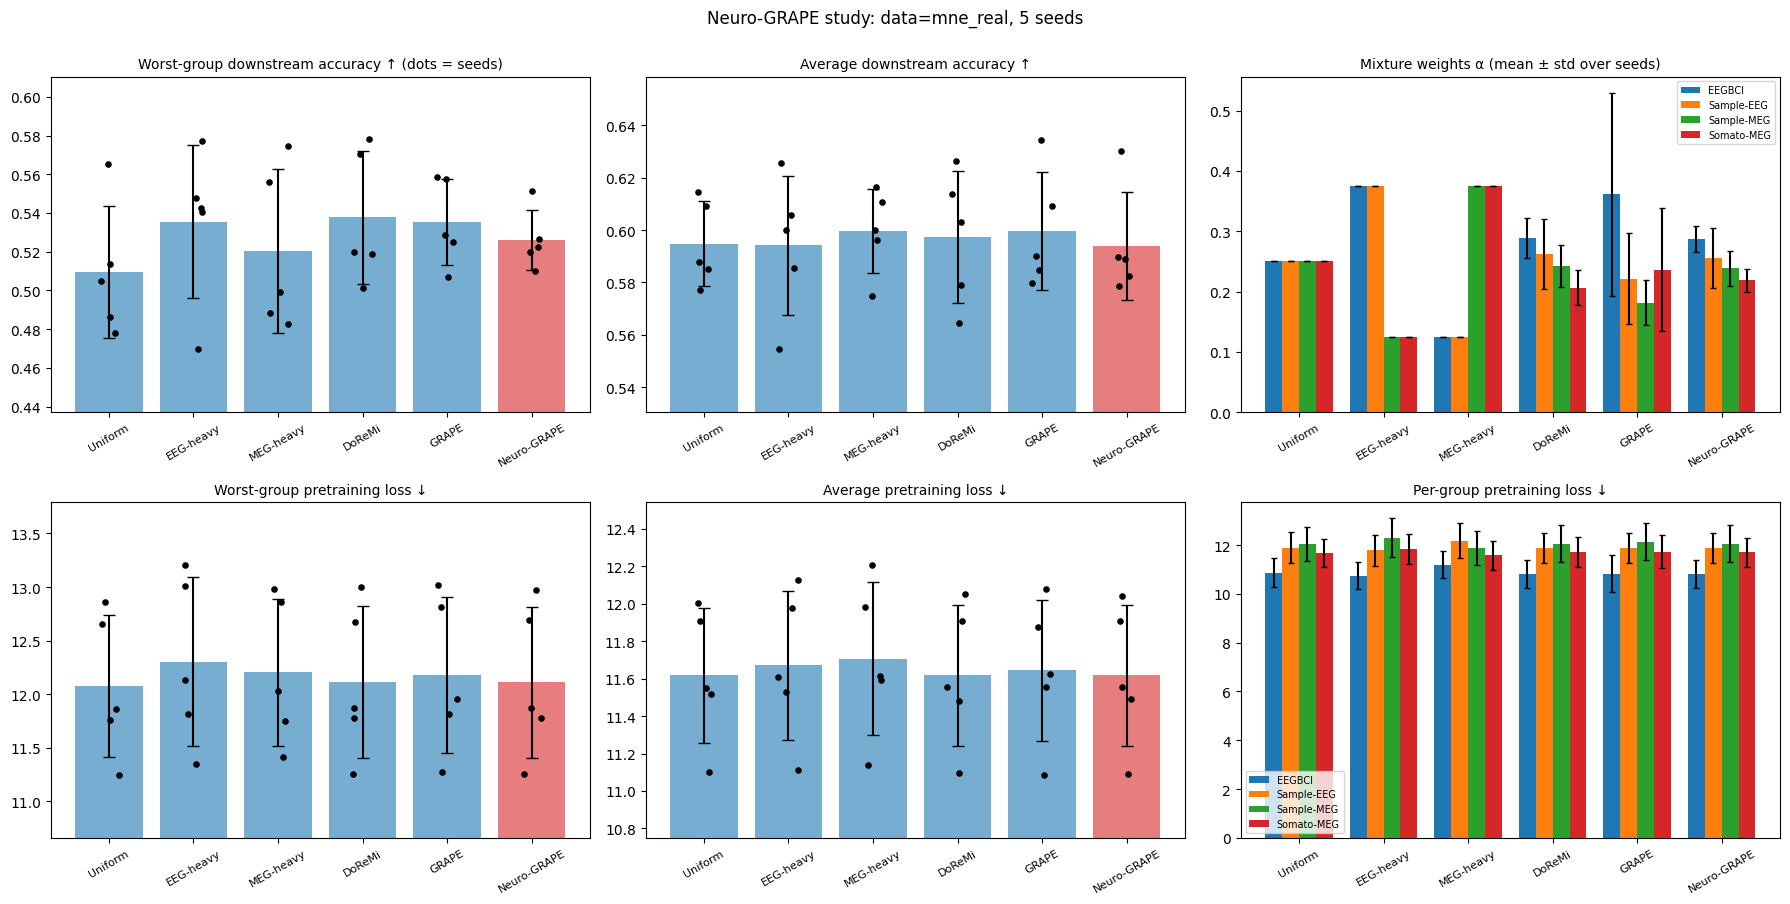

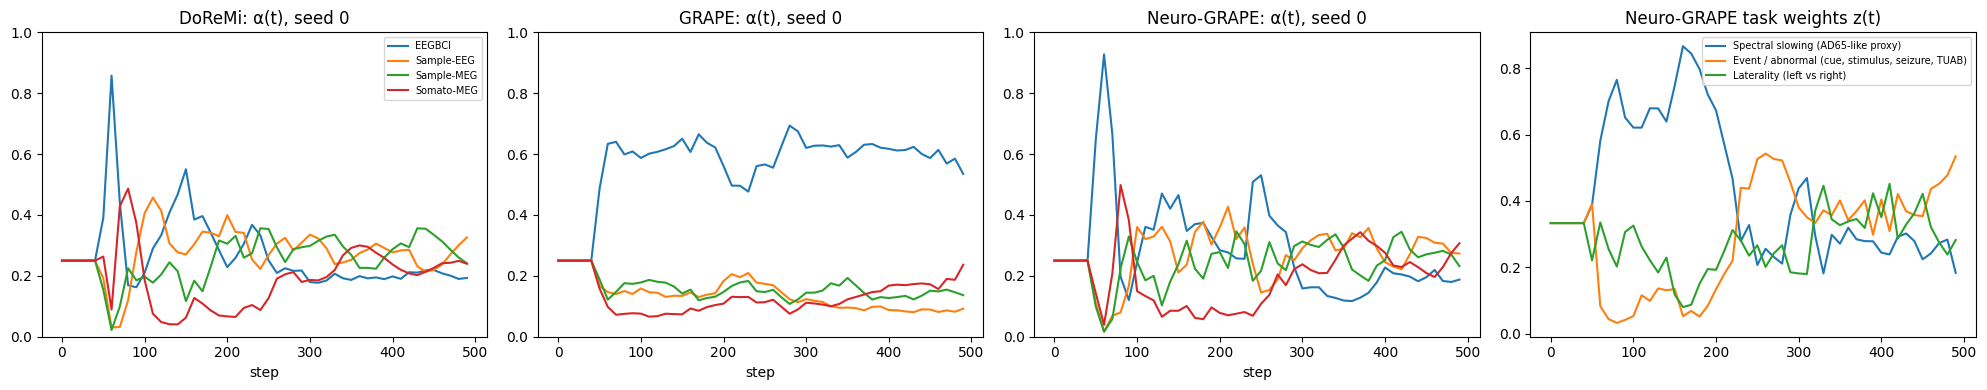

In [ ]:
colors = ["C3" if m == "Neuro-GRAPE" else "C0" for m in METHODS]
x = np.arange(len(METHODS)); rng = np.random.RandomState(0)

def bars(ax, vals, title, ylim_pad=True):
    m, s = vals.mean(0), sd(vals)
    ax.bar(x, m, yerr=s, capsize=4, color=colors, alpha=0.6)
    for si in range(vals.shape[0]): ax.scatter(x + (rng.rand(len(x)) - 0.5) * 0.25, vals[si], s=14, c="k", zorder=3)
    if ylim_pad:
        lo, hi = (vals.min() - 0.0), vals.max(); pad = 0.3 * (hi - lo) + 1e-6; ax.set_ylim(lo - pad, hi + pad)
    ax.set_xticks(x); ax.set_xticklabels(METHODS, rotation=30, fontsize=8); ax.set_title(title, fontsize=10)

def grouped(ax, arr, title):                              # arr (S,M,K)
    for k in range(K):
        ax.bar(x + (k - (K - 1) / 2) * 0.2, arr[:, :, k].mean(0), 0.2, yerr=sd(arr[:, :, k]), capsize=2, label=GROUPS[k])
    ax.set_xticks(x); ax.set_xticklabels(METHODS, rotation=30, fontsize=8); ax.set_title(title, fontsize=10); ax.legend(fontsize=7)

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
bars(ax[0, 0], MET["worst_acc"], "Worst-group downstream accuracy ↑ (dots = seeds)")
bars(ax[0, 1], MET["mean_acc"],  "Average downstream accuracy ↑")
grouped(ax[0, 2], ALPHA, "Mixture weights α (mean ± std over seeds)")
bars(ax[1, 0], MET["worst_loss"], "Worst-group pretraining loss ↓")
bars(ax[1, 1], MET["mean_loss"],  "Average pretraining loss ↓")
grouped(ax[1, 2], LOSS, "Per-group pretraining loss ↓")
plt.suptitle(f"Neuro-GRAPE study: data={DATA_SOURCE}, {S_} seeds", y=1.0)
plt.tight_layout(); plt.savefig("neurogrape_results.png", dpi=130); plt.show()

# adaptive feedback loop for the first seed
s0 = SEEDS[0]; fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for j, lab in enumerate(["DoReMi", "GRAPE", "Neuro-GRAPE"]):
    tr = np.array(RES[s0]["traj"][lab])
    for k in range(K): ax[j].plot(np.arange(len(tr)) * 10, tr[:, k], label=GROUPS[k])
    ax[j].set_title(f"{lab}: α(t), seed {s0}"); ax[j].set_xlabel("step"); ax[j].set_ylim(0, 1)
ax[0].legend(fontsize=7)
zt = np.array(RES[s0]["traj"]["task_weights"])
for n in range(N_TASK): ax[3].plot(np.arange(len(zt)) * 10, zt[:, n], label=TASKS[n][0])
ax[3].set_title("Neuro-GRAPE task weights z(t)"); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.savefig("neurogrape_alpha_trajectories.png", dpi=130); plt.show()

## Diagnostics: is the worst group a *representation* problem or a *weighting* problem?
v1 showed Cam-CAN reconstructing poorly. If a group is hard because the **tokenizer represents it badly** (low reconstruction PCC, high-entropy / poorly used codes), then no mixture weighting can fix it, and a worst-group "failure" of Neuro-GRAPE would say nothing about the method. We test this four ways:

1. **Tokenizer quality vs difficulty**: per-group reconstruction PCC, codebook usage, the context-free token-entropy floor, and how much the Uniform model improves on that floor.
2. **Fixed-effects regression** over every (seed, method, group): how much does a group's loss move per doubling of its weight α, after removing group and seed effects, compared with the gap between the hardest group and the rest?
3. **α-sweep control**: directly vary the hardest group's weight 0.10 → 0.70.
4. **Tokenizer ablation**: retrain the tokenizer with extra focus on poorly-reconstructed groups (same budget) and check whether the worst-group gap and the Neuro-GRAPE-vs-Uniform difference change.

In [ ]:
PCC   = np.array([RES[s]["tok"]["pcc"] for s in SEEDS])          # (S,K)
CODES = np.array([RES[s]["tok"]["codes"] for s in SEEDS])
FLOOR = np.array([RES[s]["floor"] for s in SEEDS])
iU = METHODS.index("Uniform")
UL, UA = LOSS[:, iU, :], ACC[:, iU, :]

print("1) Tokenizer quality and difficulty per group (mean ± std over seeds)")
show(pd.DataFrame({
    "train windows": [NTRAIN[g] for g in GROUPS],
    "recon PCC ↑":   [pm(PCC[:, k].mean(), sd(PCC)[k]) for k in range(K)],
    "codebook used": [pm(CODES[:, k].mean(), sd(CODES)[k], 2) for k in range(K)],
    "token-entropy floor (context-free loss)": [pm(FLOOR[:, k].mean(), sd(FLOOR)[k]) for k in range(K)],
    "Uniform model loss": [pm(UL[:, k].mean(), sd(UL)[k]) for k in range(K)],
    "gain over floor ↑ (learned from context)": [pm((FLOOR - UL)[:, k].mean(), sd(FLOOR - UL)[k]) for k in range(K)],
    "Uniform downstream acc": [pm(UA[:, k].mean(), sd(UA)[k]) for k in range(K)],
}, index=GROUPS))

def corr(a, b):
    a, b = np.ravel(a), np.ravel(b)
    return np.corrcoef(a, b)[0, 1] if a.std() > 0 and b.std() > 0 else float("nan")
print(f"\n   across (seed × group), Uniform model:  corr(loss, recon PCC) = {corr(UL, PCC):+.2f}   corr(loss, entropy floor) = {corr(UL, FLOOR):+.2f}   corr(acc, recon PCC) = {corr(UA, PCC):+.2f}")
hard_cnt = {g: int((UL.argmax(1) == k).sum()) for k, g in enumerate(GROUPS)}
print("   hardest group under Uniform (by loss), count over seeds:", hard_cnt)
print("   (exploratory; group identity is confounded with tokenizer quality here, so use this together with checks 2-4.)")

print("\n2) Fixed-effects regression: Δ loss of a group per doubling of its weight α (group + seed effects removed)")
def alpha_effect(seed_idx):
    y, Z = [], []
    for si, s in enumerate(seed_idx):
        for m in range(len(METHODS)):
            for k in range(K):
                z = np.zeros(len(seed_idx) + K + 1); z[si] = 1; z[len(seed_idx) + k] = 1; z[-1] = np.log(ALPHA[s, m, k])
                Z.append(z); y.append(LOSS[s, m, k])
    return np.linalg.lstsq(np.array(Z), np.array(y), rcond=None)[0][-1] * np.log(2)
eff = alpha_effect(list(range(S_)))
gap = (UL.max(1) - np.median(UL, 1)).mean()
if S_ >= 3:
    bs = np.array([alpha_effect(list(np.random.RandomState(b).randint(0, S_, S_))) for b in range(200)])
    print(f"   effect per doubling of α: {eff:+.4f} loss   (bootstrap-over-seeds 95% CI [{np.percentile(bs, 2.5):+.4f}, {np.percentile(bs, 97.5):+.4f}])")
else:
    print(f"   effect per doubling of α: {eff:+.4f} loss   (need ≥3 seeds for a CI)")
print(f"   gap between hardest group and the median group under Uniform: {gap:.3f} loss")
print("   -> if |effect| is small relative to the gap, weighting alone cannot close it: the gap is mostly set by representation / group difficulty.")

1) Tokenizer quality and difficulty per group (mean ± std over seeds)


,train windows,recon PCC ↑,codebook used,token-entropy floor (context-free loss),Uniform model loss,gain over floor ↑ (learned from context),Uniform downstream acc
EEGBCI,3000,0.375 ± 0.040,0.99 ± 0.02,13.828 ± 0.919,10.871 ± 0.585,2.956 ± 0.524,0.595 ± 0.047
Sample-EEG,222,0.303 ± 0.084,0.99 ± 0.02,14.487 ± 0.352,11.896 ± 0.632,2.592 ± 0.691,0.627 ± 0.035
Sample-MEG,222,0.157 ± 0.043,0.98 ± 0.01,14.694 ± 0.364,12.029 ± 0.702,2.665 ± 0.827,0.521 ± 0.044
Somato-MEG,288,0.141 ± 0.048,0.98 ± 0.02,14.072 ± 0.510,11.671 ± 0.567,2.401 ± 0.946,0.636 ± 0.033



   across (seed × group), Uniform model:  corr(loss, recon PCC) = -0.54   corr(loss, entropy floor) = +0.44   corr(acc, recon PCC) = +0.16
   hardest group under Uniform (by loss), count over seeds: {'EEGBCI': 0, 'Sample-EEG': 2, 'Sample-MEG': 3, 'Somato-MEG': 0}
   (exploratory; group identity is confounded with tokenizer quality here, so use this together with checks 2-4.)

2) Fixed-effects regression: Δ loss of a group per doubling of its weight α (group + seed effects removed)
   effect per doubling of α: -0.2810 loss   (bootstrap-over-seeds 95% CI [-0.3700, -0.1822])
   gap between hardest group and the median group under Uniform: 0.299 loss
   -> if |effect| is small relative to the gap, weighting alone cannot close it: the gap is mostly set by representation / group difficulty.


3) α-sweep control: weight on the hardest group (chosen on val from the Uniform model) vs its test loss
   hardest groups: ['Sample-MEG', 'Sample-MEG', 'Sample-MEG']


,hardest-group loss ↓,worst-group loss ↓,average loss ↓,hardest-group acc ↑
weight on hardest group,,,,
0.10,12.126 ± 0.839,12.126 ± 0.839,11.551 ± 0.443,0.552 ± 0.042
0.25,11.919 ± 0.708,11.920 ± 0.707,11.519 ± 0.406,0.541 ± 0.047
0.40,11.794 ± 0.659,11.911 ± 0.720,11.527 ± 0.412,0.558 ± 0.050
0.55,11.702 ± 0.603,11.974 ± 0.734,11.564 ± 0.398,0.557 ± 0.029
0.70,11.650 ± 0.606,12.162 ± 0.816,11.662 ± 0.449,0.540 ± 0.009


   slope of hardest-group loss vs its weight: -0.780 per unit weight (±0.382 over seeds)


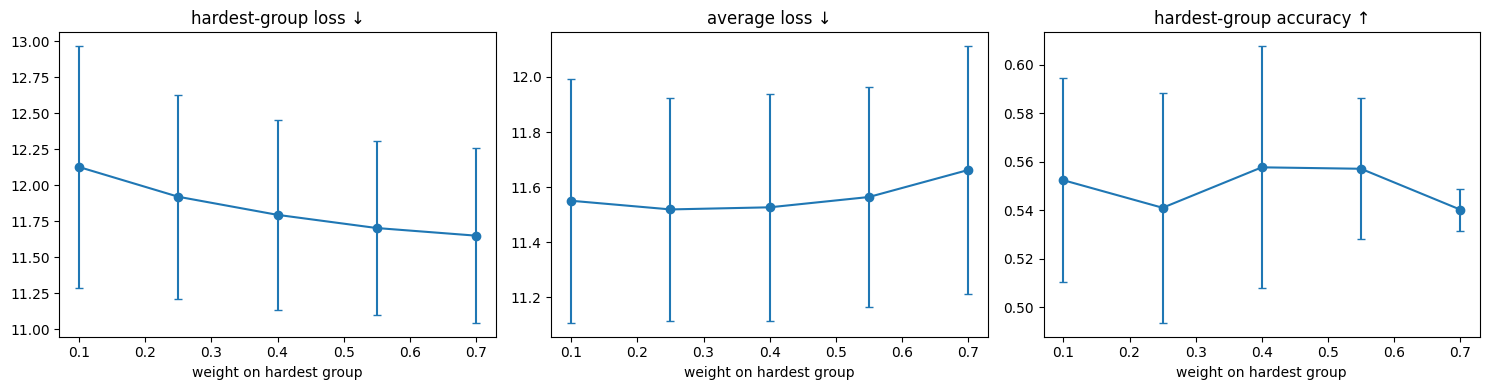

   -> a flat hardest-group curve means weighting is not the lever for that group; a steep curve with a flat/slightly worse average means it is.


In [ ]:
print("3) α-sweep control: weight on the hardest group (chosen on val from the Uniform model) vs its test loss")
sw = [RES[s]["sweep"] for s in SEEDS if RES[s].get("sweep")]
if not sw: print("   (no sweep results; set RUN_ALPHA_SWEEP=True)")
else:
    Ws = [p["w"] for p in sw[0]["points"]]
    hard = np.array([[p["loss"][d["hardest"]] for p in d["points"]] for d in sw])       # (n, |W|)
    avgl = np.array([[np.mean(p["loss"]) for p in d["points"]] for d in sw])
    hacc = np.array([[p["acc"][d["hardest"]] for p in d["points"]] for d in sw])
    wstl = np.array([[np.max(p["loss"]) for p in d["points"]] for d in sw])
    print("   hardest groups:", [d["group"] for d in sw])
    show(pd.DataFrame({"weight on hardest group": Ws,
                       "hardest-group loss ↓": [pm(hard[:, i].mean(), sd(hard)[i]) for i in range(len(Ws))],
                       "worst-group loss ↓":   [pm(wstl[:, i].mean(), sd(wstl)[i]) for i in range(len(Ws))],
                       "average loss ↓":       [pm(avgl[:, i].mean(), sd(avgl)[i]) for i in range(len(Ws))],
                       "hardest-group acc ↑":  [pm(hacc[:, i].mean(), sd(hacc)[i]) for i in range(len(Ws))]}).set_index("weight on hardest group"))
    slopes = np.array([np.polyfit(Ws, hard[i], 1)[0] for i in range(len(sw))])
    print(f"   slope of hardest-group loss vs its weight: {slopes.mean():+.3f} per unit weight (±{slopes.std(ddof=1) if len(sw)>1 else float('nan'):.3f} over seeds)")
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for a_, arr, t in [(ax[0], hard, "hardest-group loss ↓"), (ax[1], avgl, "average loss ↓"), (ax[2], hacc, "hardest-group accuracy ↑")]:
        a_.errorbar(Ws, arr.mean(0), yerr=sd(arr), marker="o", capsize=3); a_.set_xlabel("weight on hardest group"); a_.set_title(t)
    plt.tight_layout(); plt.savefig("neurogrape_alpha_sweep.png", dpi=130); plt.show()
    print("   -> a flat hardest-group curve means weighting is not the lever for that group; a steep curve with a flat/slightly worse average means it is.")

In [ ]:
print("4) Tokenizer ablation: does a better tokenizer for the weak groups change the picture? (same total tokenizer budget)")
RES_F = {}
if RUN_TOK_ABLATION:
    for s in range(ABL_SEEDS): RES_F[s] = run_seed(s, "focus")
    ab = sorted(RES_F)
    def ng_minus_uniform(R, s, key, fn):
        r = R["methods"]; return fn(r["Neuro-GRAPE"][key]) - fn(r["Uniform"][key])
    rows = []
    for s in ab:
        for mode, R in [("round-robin (default)", RES[s]), ("focus on hard groups", RES_F[s])]:
            rows.append({"seed": s, "tokenizer": mode, "min recon PCC": f"{min(R['tok']['pcc']):.3f}",
                         "Uniform worst loss": f"{max(R['methods']['Uniform']['loss']):.3f}",
                         "Uniform worst acc": f"{min(R['methods']['Uniform']['acc']):.3f}",
                         "NG−Uniform worst acc": f"{ng_minus_uniform(R, s, 'acc', min):+.3f}",
                         "NG−Uniform worst loss": f"{ng_minus_uniform(R, s, 'loss', max):+.3f}"})
    show(pd.DataFrame(rows).set_index(["seed", "tokenizer"]))
    print("   -> if the focused tokenizer raises the weak group's PCC and shrinks the worst-group gap for *all* methods, that gap was representational.")
    print("      If Neuro-GRAPE's advantage over Uniform appears/disappears with the tokenizer, the method's benefit depends on representation quality, not only on weighting.")
else:
    print("   (skipped; set RUN_TOK_ABLATION=True)")

4) Tokenizer ablation: does a better tokenizer for the weak groups change the picture? (same total tokenizer budget)
[seed 0 | tok=focus] tokenizer PCC per group {'EEGBCI': np.float64(0.435), 'Sample-EEG': np.float64(0.378), 'Sample-MEG': np.float64(0.205), 'Somato-MEG': np.float64(0.188)}  (19s)
[seed 0 | tok=focus] reference (Uniform) trained  (29s)
[seed 0 | tok=focus] proxy DoReMi      learned alpha = [0.265 0.233 0.257 0.244]  (44s)
[seed 0 | tok=focus] proxy GRAPE       learned alpha = [0.481 0.199 0.12  0.199]  (61s)
[seed 0 | tok=focus] proxy Neuro-GRAPE learned alpha = [0.291 0.215 0.234 0.26 ]  (81s)
[seed 0 | tok=focus] final models trained  (112s)
[seed 0 | tok=focus] evaluated: Uniform: acc 0.581/worst 0.551  DoReMi: acc 0.581/worst 0.537  GRAPE: acc 0.561/worst 0.532  Neuro-GRAPE: acc 0.589/worst 0.510  (115s)
[seed 1 | tok=focus] tokenizer PCC per group {'EEGBCI': np.float64(0.238), 'Sample-EEG': np.float64(0.216), 'Sample-MEG': np.float64(0.107), 'Somato-MEG': np.float6

min recon PCC Uniform worst loss Uniform worst acc  \
seed tokenizer                                                                  
0    round-robin (default)         0.135             12.654             0.486   
     focus on hard groups          0.188             10.768             0.551   
1    round-robin (default)         0.188             11.863             0.565   
     focus on hard groups          0.072             11.693             0.549   
2    round-robin (default)         0.174             11.244             0.514   
     focus on hard groups          0.101             11.023             0.543   

                           NG−Uniform worst acc NG−Uniform worst loss  
seed tokenizer                                                         
0    round-robin (default)               +0.024                +0.034  
     focus on hard groups                -0.040                +0.015  
1    round-robin (default)               -0.014                +0.009  
     focus on hard groups                +0.010                -0.001  
2    round-robin (default)               +0.013                +0.006  
     focus on hard groups                +0.005                +0.027

   -> if the focused tokenizer raises the weak group's PCC and shrinks the worst-group gap for *all* methods, that gap was representational.
      If Neuro-GRAPE's advantage over Uniform appears/disappears with the tokenizer, the method's benefit depends on representation quality, not only on weighting.


## Save results and summary
Writes `neurogrape_summary.csv` (mean ± std table), `neurogrape_all_seeds.json` (every per-seed number) plus the PNGs. The per-seed checkpoints stay in `results/`.

In [ ]:
tab.to_csv("neurogrape_summary.csv")
json.dump(dict(data_source=DATA_SOURCE, provenance=PROV, scenario=SCENARIO, seeds=SEEDS, methods=METHODS, groups=GROUPS, specs=SPECS,
               per_seed={str(s): RES[s] for s in SEEDS}, tokenizer_ablation={str(s): RES_F[s] for s in RES_F}),
          open("neurogrape_all_seeds.json", "w"))
print("saved neurogrape_summary.csv, neurogrape_all_seeds.json, neurogrape_results.png, neurogrape_alpha_trajectories.png, neurogrape_alpha_sweep.png, neurogrape_data_overview.png")
try:
    from google.colab import files
    for f in ["neurogrape_summary.csv", "neurogrape_all_seeds.json", "neurogrape_results.png"]: files.download(f)
except Exception:
    pass

saved neurogrape_summary.csv, neurogrape_all_seeds.json, neurogrape_results.png, neurogrape_alpha_trajectories.png, neurogrape_alpha_sweep.png, neurogrape_data_overview.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to report these results
* Read the **provenance table** first and say what the groups actually are. `mne_sim`: *"in a controlled simulation with heterogeneous groups, over N seeds"*. `mne_real` with public stand-ins: *"on public EEG/MEG recordings from MNE (EEGBCI, MNE-sample, MNE-somato), N seeds"*, and name the single-subject groups as such. Only the `kind="local"` runs may be described as results on TUH / CHB-MIT / OMEGA / Cam-CAN.
* Lead with the paired differences (Neuro-GRAPE vs Uniform / DoReMi / GRAPE) on **worst-group accuracy and loss**, and state the **average non-inferiority** result next to them. On real data "accuracy" means balanced accuracy and the slowing task is a spectral proxy.
* On real data the seed variance is split + initialisation variance (the recordings are fixed). With single-subject groups the test sets are small: expect wide intervals and say so.
* If the diagnostics show weighting barely moves the hardest group (flat α-sweep, small per-doubling effect, or the gap shrinks with a better tokenizer), report that the worst-group gap is **representation-limited**.
* Before submitting: run once with `QUICK=False`, `N_SEEDS≥5`, GPU runtime, and keep `results/` + `neurogrape_all_seeds.json` (they contain the provenance of every number).